<a href="https://colab.research.google.com/github/all3048/Beginning-Bioinformatics/blob/AncD1/Stage1b_alignment_tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stage 1b — Alignment and tree

**Input:** `ancd1_set_final.fasta` from Stage 1a.
**Output:** a rooted, bootstrapped tree plus an iTOL annotation file for the figure.

Three things here are deliberate and belong in your methods section:

1. **Two aligners.** MAFFT L-INS-i is primary, Clustal Omega is a cross-check. Stage 3
   scores individual alignment columns, so a misplaced gap becomes a false
   "specificity-determining" residue. Agreement between two independent aligners is the
   cheapest defense against that.
2. **Three rootings.** Outgroup, ADH-clade, and midpoint. Rooting is the one decision that
   changes which clade looks ancestral, and your Stage 2 reconstruction sits directly on
   top of it. If the FGD/FSD split holds position under all three, say so in one sentence
   and nobody asks again.
3. **Names are sanitized before alignment.** IQ-TREE mangles pipe characters in taxon
   names. We rename to safe IDs and keep a mapping, so the tree tips match the FASTA.

## Step 2.0 — Install

In [2]:
# ============================================================
#  STEP 2.0 - INSTALL (robust)
#  Installs each tool separately so one bad package name does
#  not silently abort the whole install, and verifies each.
# ============================================================
import subprocess, shutil, os, sys

def sh(cmd, quiet=True):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if not quiet and r.returncode != 0:
        print((r.stderr or r.stdout)[-600:])
    return r.returncode == 0

print("updating package lists ...")
sh("apt-get -qq update")

# ---- plain apt packages ----
for pkg, binary in [("mafft", "mafft"), ("clustalo", "clustalo"), ("trimal", "trimal")]:
    if shutil.which(binary):
        print(f"  {binary:10s} already present")
        continue
    print(f"  installing {pkg} ...", end=" ", flush=True)
    ok = sh(f"apt-get -qq install -y {pkg}")
    print("ok" if shutil.which(binary) else f"FAILED (apt returned {ok})")

# ---- IQ-TREE: package name varies, so try several, then a binary ----
def have_iqtree():
    return shutil.which("iqtree") or shutil.which("iqtree2")

if not have_iqtree():
    for pkg in ["iqtree", "iqtree2"]:
        print(f"  trying apt package {pkg} ...", end=" ", flush=True)
        sh(f"apt-get -qq install -y {pkg}")
        if have_iqtree():
            print("ok"); break
        print("no")

if not have_iqtree():
    print("  apt has no iqtree; downloading the official binary ...")
    url = ("https://github.com/iqtree/iqtree2/releases/download/v2.3.6/"
           "iqtree-2.3.6-Linux-intel.tar.gz")
    if sh(f"wget -q -O /tmp/iqtree.tar.gz {url}") and os.path.getsize("/tmp/iqtree.tar.gz") > 1_000_000:
        sh("mkdir -p /opt/iqtree && tar -xzf /tmp/iqtree.tar.gz -C /opt/iqtree --strip-components=1")
        cand = "/opt/iqtree/bin/iqtree2"
        if os.path.exists(cand):
            sh(f"chmod +x {cand} && ln -sf {cand} /usr/local/bin/iqtree2")
            print("  installed IQ-TREE 2 binary")
        else:
            print("  downloaded but binary not where expected; check /opt/iqtree")
    else:
        print("  download failed")

# ---- report ----
print("\nverification:")
IQTREE = shutil.which("iqtree2") or shutil.which("iqtree")
missing = []
for name, path in [("mafft", shutil.which("mafft")),
                   ("clustalo", shutil.which("clustalo")),
                   ("trimal", shutil.which("trimal")),
                   ("iqtree", IQTREE)]:
    if path:
        v = subprocess.run([path, "--version"], capture_output=True, text=True)
        line = (v.stdout + v.stderr).strip().split("\n")[0][:55]
        print(f"  {name:10s} {path}")
        print(f"  {'':10s} {line}")
    else:
        print(f"  {name:10s} MISSING")
        missing.append(name)

if missing:
    print(f"\n*** missing: {', '.join(missing)} - tell Claude which ones.")
else:
    print("\nAll four tools available.")

# Stage 1b calls iqtree; make sure that name works whichever got installed.
if IQTREE and not shutil.which("iqtree"):
    sh(f"ln -sf {IQTREE} /usr/local/bin/iqtree")
    print("linked iqtree2 -> iqtree so the later cells work unchanged")

IQTREE_CMD = "iqtree"
print(f"\nIQTREE_CMD = {IQTREE_CMD!r}")

updating package lists ...
  mafft      already present
  clustalo   already present
  installing trimal ... FAILED (apt returned False)

verification:
  mafft      /usr/bin/mafft
             v7.505 (2022/Apr/10)
  clustalo   /usr/bin/clustalo
             1.2.4
  trimal     MISSING
  iqtree     /usr/bin/iqtree2
             IQ-TREE multicore version 2.0.7 for Linux 64-bit built 

*** missing: trimal - tell Claude which ones.

IQTREE_CMD = 'iqtree'


In [3]:
!pip install -q biopython
print("biopython installed")

biopython installed


In [4]:
import os, re, json, subprocess, shutil
from collections import Counter, defaultdict
from Bio import SeqIO, Phylo
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
import matplotlib.pyplot as plt

WORK = "/content/ancd1_phylo"
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)

INPUT = "ancd1_set_final.fasta"

# look in the usual places before asking for an upload
if not os.path.exists(INPUT):
    for cand in ["/content/ancd1_set_final.fasta",
                 "/content/drive/MyDrive/ancd1_set_final.fasta",
                 os.path.expanduser("~/ancd1_set_final.fasta")]:
        if os.path.exists(cand):
            shutil.copy(cand, INPUT)
            print(f"copied from {cand}")
            break

if not os.path.exists(INPUT):
    print(f"{INPUT} not found. Choose the file from your computer:\n")
    from google.colab import files
    up = files.upload()
    for fname in up:
        if fname.endswith((".fasta", ".fa", ".faa")):
            shutil.move(f"/content/{fname}" if os.path.exists(f"/content/{fname}") else fname,
                        INPUT)
            print(f"\nsaved as {INPUT}")
            break

assert os.path.exists(INPUT), f"still no {INPUT} - upload it and re-run this cell"

records = list(SeqIO.parse(INPUT, "fasta"))
N = len(records)
print(f"{N} sequences loaded from {INPUT}")
if N != 239:
    print(f"*** expected 239 sequences, got {N} - check you uploaded the right file")

ancd1_set_final.fasta not found. Choose the file from your computer:



Saving ancd1_set_final.fasta to ancd1_set_final.fasta

saved as ancd1_set_final.fasta
239 sequences loaded from ancd1_set_final.fasta


## Step 2.1 — Sanitize names, choose the aligner

IQ-TREE replaces `|` and other punctuation in taxon names, which silently breaks the
mapping between your tree tips and your reference labels. We rename everything to
`seq0001`-style IDs up front and keep `name_map.json` to translate back.

In [5]:
name_map, safe_records = {}, []

for i, rec in enumerate(records, start=1):
    safe = f"seq{i:04d}"
    original = rec.id
    # Keep clade tag if the record carries one (references look like LABEL|ACC|CLADE)
    parts = original.split("|")
    if len(parts) == 3:
        label, acc, clade = parts
    elif original == "AncD1":
        label, acc, clade = "AncD1", "THIS_STUDY", "ANCESTOR"
    else:
        label, acc, clade = original, original, "homolog"

    name_map[safe] = {
        "original": original,
        "label": label,
        "accession": acc,
        "clade": clade,
        "description": rec.description,
    }
    safe_records.append(SeqRecord(rec.seq, id=safe, description=""))

SeqIO.write(safe_records, "input_safe.fasta", "fasta")
with open("name_map.json", "w") as fh:
    json.dump(name_map, fh, indent=1)

clades = Counter(v["clade"] for v in name_map.values())
print("sequences by clade tag:")
for c, n in clades.most_common():
    print(f"  {c:12s} {n}")

# Aligner choice depends on set size: L-INS-i is O(n^2) and impractical above ~500.
if N <= 500:
    MAFFT_MODE, MAFFT_FLAGS = "L-INS-i", ["--localpair", "--maxiterate", "1000"]
else:
    MAFFT_MODE, MAFFT_FLAGS = "FFT-NS-2", ["--retree", "2", "--maxiterate", "0"]

print(f"\n{N} sequences -> MAFFT {MAFFT_MODE}")
print("Record this in your methods: MAFFT v7 " + MAFFT_MODE +
      ", Clustal Omega cross-check, trimAl gappyout, IQ-TREE ModelFinder.")

sequences by clade tag:
  homolog      230
  DH2_FGD      3
  DH3_FSD      2
  DH1_ADH      2
  ANCESTOR     1
  OUTGROUP     1

239 sequences -> MAFFT L-INS-i
Record this in your methods: MAFFT v7 L-INS-i, Clustal Omega cross-check, trimAl gappyout, IQ-TREE ModelFinder.


## Step 2.2 — Align (both aligners)

In [6]:
def run(cmd, outfile=None, label=""):
    print(f"  running {label or cmd[0]} ...", end=" ", flush=True)
    import time; t0 = time.time()
    if outfile:
        with open(outfile, "w") as fh:
            r = subprocess.run(cmd, stdout=fh, stderr=subprocess.PIPE, text=True)
    else:
        r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print("FAILED")
        print((r.stderr or "")[-2000:])
        raise RuntimeError(f"{label} failed")
    print(f"ok ({time.time()-t0:.0f}s)")
    return r

run(["mafft"] + MAFFT_FLAGS + ["--anysymbol", "--quiet", "input_safe.fasta"],
    outfile="aln_mafft.fasta", label=f"MAFFT {MAFFT_MODE}")

run(["clustalo", "-i", "input_safe.fasta", "-o", "aln_clustalo.fasta",
     "--outfmt=fasta", "--force", "--threads=2"],
    label="Clustal Omega")

for f in ["aln_mafft.fasta", "aln_clustalo.fasta"]:
    a = list(SeqIO.parse(f, "fasta"))
    L = len(a[0].seq)
    gaps = sum(str(r.seq).count("-") for r in a) / (len(a) * L)
    print(f"  {f:22s} {len(a)} seqs x {L} columns, {gaps*100:.1f}% gaps")

  running MAFFT L-INS-i ... ok (64s)
  running Clustal Omega ... ok (5s)
  aln_mafft.fasta        239 seqs x 653 columns, 48.4% gaps
  aln_clustalo.fasta     239 seqs x 571 columns, 41.0% gaps


### How different are the two alignments?

A large length difference means the aligners disagree about how much indel structure
exists, which is a warning sign for Stage 3. Identical-length alignments are not
necessarily identical alignments, but a big gap in column count definitely means
disagreement.

In [7]:
m = list(SeqIO.parse("aln_mafft.fasta", "fasta"))
c = list(SeqIO.parse("aln_clustalo.fasta", "fasta"))
Lm, Lc = len(m[0].seq), len(c[0].seq)

print(f"MAFFT   : {Lm} columns")
print(f"ClustalO: {Lc} columns")
print(f"difference: {abs(Lm-Lc)} columns ({100*abs(Lm-Lc)/max(Lm,Lc):.1f}%)")
print()
if abs(Lm - Lc) / max(Lm, Lc) < 0.10:
    print("Under 10% - the aligners broadly agree. Proceed with MAFFT.")
else:
    print("Over 10% - substantial disagreement about indel structure.")
    print("Still proceed with MAFFT, but in Stage 3 you MUST verify that top-ranked")
    print("positions survive both alignments before reporting any of them.")

MAFFT   : 653 columns
ClustalO: 571 columns
difference: 82 columns (12.6%)

Over 10% - substantial disagreement about indel structure.
Still proceed with MAFFT, but in Stage 3 you MUST verify that top-ranked
positions survive both alignments before reporting any of them.


In [8]:
import subprocess, shutil, os

def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    return r.returncode == 0, (r.stdout + r.stderr)

HAVE_TRIMAL = bool(shutil.which("trimal"))

if not HAVE_TRIMAL:
    print("building trimAl from source (about 30 s) ...")
    ok, log = sh(
        "cd /tmp && rm -rf trimal && "
        "git clone -q --depth 1 https://github.com/inab/trimal.git && "
        "cd trimal/source && make -j2 > /dev/null 2>&1 && "
        "cp trimal readal /usr/local/bin/ 2>/dev/null"
    )
    HAVE_TRIMAL = bool(shutil.which("trimal"))
    print("  trimAl available" if HAVE_TRIMAL else "  build failed - using the Python fallback")

print(f"\nHAVE_TRIMAL = {HAVE_TRIMAL}")

building trimAl from source (about 30 s) ...
  trimAl available

HAVE_TRIMAL = True


In [9]:
from Bio import SeqIO, AlignIO
from Bio.Align import MultipleSeqAlignment
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
import subprocess

GAP_THRESHOLD = 0.50     # drop a column if more than this fraction is gaps

aln_in, aln_out = "aln_mafft.fasta", "aln_trimmed.fasta"
m = list(SeqIO.parse(aln_in, "fasta"))
Lm = len(m[0].seq)
print(f"input alignment: {len(m)} sequences x {Lm} columns")

if HAVE_TRIMAL:
    r = subprocess.run(["trimal", "-in", aln_in, "-out", aln_out, "-gappyout"],
                       capture_output=True, text=True)
    if r.returncode != 0:
        print("trimal failed:", (r.stderr or "")[-400:])
        raise RuntimeError("trimal run failed")
    TRIM_METHOD = "trimAl -gappyout"
else:
    n = len(m)
    keep = [i for i in range(Lm)
            if sum(1 for rec in m if rec.seq[i] == "-") / n <= GAP_THRESHOLD]
    trimmed = MultipleSeqAlignment([
        SeqRecord(Seq("".join(str(rec.seq)[i] for i in keep)),
                  id=rec.id, description="")
        for rec in m
    ])
    AlignIO.write(trimmed, aln_out, "fasta")
    TRIM_METHOD = f"gap threshold, columns with >{GAP_THRESHOLD:.0%} gaps removed"

t = list(SeqIO.parse(aln_out, "fasta"))
Lt = len(t[0].seq)
frac = Lt / Lm
print(f"method: {TRIM_METHOD}")
print(f"  {Lm} -> {Lt} columns ({frac*100:.1f}% retained)")

if frac < 0.30:
    print("\n*** under 30% retained - likely fragments in the set. Tell Claude.")
elif frac < 0.50:
    print("\nLow-ish but workable; expect modest support on deep branches.")
else:
    print("\nHealthy. Proceed to the tree.")

input alignment: 239 sequences x 653 columns
method: trimAl -gappyout
  653 -> 313 columns (47.9% retained)

Low-ish but workable; expect modest support on deep branches.


## Step 2.3 — Trim

`trimAl -gappyout` removes columns that are mostly gaps. These carry almost no
phylogenetic signal and actively hurt — a column present in 5 of 300 sequences
contributes noise to every branch length estimate.

Check the retained fraction. Below ~30% retained means your set is too divergent or
contains fragments, and the tree will be unreliable.

## Step 2.4 — Build the tree

IQ-TREE with ModelFinder (`-m MFP`) picks the substitution model by BIC rather than you
guessing. Two support measures:

- **`-bb 1000`** ultrafast bootstrap. Read these as well-supported at **>= 95**.
- **`-alrt 1000`** SH-aLRT. Well-supported at **>= 80**.

Report both; a branch that satisfies both is solid. This is the long cell — expect
several minutes to tens of minutes depending on set size.

In [10]:
import time, subprocess
t0 = time.time()
r = subprocess.run(
    ["iqtree", "-s", "aln_trimmed.fasta", "-m", "MFP",
     "-mset", "LG,WAG,JTT,Blosum62", "-mrate", "G,I+G,R4",
     "-bb", "1000", "-alrt", "1000", "-nt", "2", "-redo",
     "-pre", "ancd1_tree"],
    capture_output=True, text=True,
)
print(f"finished in {time.time()-t0:.0f}s, exit {r.returncode}")
if r.returncode != 0:
    print(r.stdout[-3000:]); print(r.stderr[-2000:])
else:
    for line in r.stdout.split("\n"):
        if "Best-fit model" in line:
            print(" ", line.strip())
    print("wrote ancd1_tree.treefile")

finished in 1905s, exit 0
  Best-fit model: LG+F+I+G4 chosen according to BIC
wrote ancd1_tree.treefile


In [11]:
from google.colab import files
for f in ["ancd1_tree.treefile", "ancd1_tree.log", "ancd1_tree.iqtree",
          "aln_trimmed.fasta", "aln_mafft.fasta", "aln_clustalo.fasta",
          "name_map.json"]:
    try:
        files.download(f)
    except Exception as e:
        print(f, "->", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import os
if os.path.exists("ancd1_tree.log"):
    txt = open("ancd1_tree.log").read()
    print(f"log is {len(txt)} chars\n")
    print("--- last 30 lines ---")
    print("\n".join(txt.strip().split("\n")[-30:]))
else:
    print("no log file - IQ-TREE may not have started properly")

log is 21456 chars

--- last 30 lines ---
Alternative NNI shows better log-likelihood -59082.211 > -59082.219
3.265 sec.
Creating bootstrap support values...
Split supports printed to NEXUS file ancd1_tree.splits.nex
Total tree length: 65.915

Total number of iterations: 245
CPU time used for tree search: 2801.109 sec (0h:46m:41s)
Wall-clock time used for tree search: 1553.964 sec (0h:25m:53s)
Total CPU time used: 2850.621 sec (0h:47m:30s)
Total wall-clock time used: 1582.594 sec (0h:26m:22s)

Computing bootstrap consensus tree...
Reading input file ancd1_tree.splits.nex...
239 taxa and 1226 splits.
Consensus tree written to ancd1_tree.contree
Reading input trees file ancd1_tree.contree
Log-likelihood of consensus tree: -59083.124

Analysis results written to: 
  IQ-TREE report:                ancd1_tree.iqtree
  Maximum-likelihood tree:       ancd1_tree.treefile
  Likelihood distances:          ancd1_tree.mldist

Ultrafast bootstrap approximation results written to:
  Split support va

In [13]:
import os
model = None
if os.path.exists("ancd1_tree.log"):
    for line in open("ancd1_tree.log"):
        if "Best-fit model" in line:
            model = line.strip(); break
print(model or "model line not found")
print()
print("METHODS:")
print(f"  Homologs were collected by BLASTP against UniProtKB (E < 1e-10) from five")
print(f"  seed sequences spanning the ancestral node and the three dehydrogenase")
print(f"  subgroups, merged, and reduced for redundancy group-wise (80% identity for")
print(f"  densely sampled lineages, 95% for the sparsely sampled FSD group), giving")
print(f"  239 sequences. These were aligned with MAFFT v7.505 ({MAFFT_MODE}) and")
print(f"  cross-checked against Clustal Omega 1.2.4. The alignment was trimmed with")
print(f"  trimAl (-gappyout), retaining {Lt} of {Lm} columns. A maximum-likelihood tree")
print(f"  was inferred with IQ-TREE 2.0.7 using ModelFinder restricted to LG, WAG, JTT")
print(f"  and Blosum62 matrices with G, I+G and R4 rate models; LG+F+I+G4 was selected")
print(f"  by BIC. Branch support is from 1000 ultrafast bootstrap and 1000 SH-aLRT")
print(f"  replicates.")

Best-fit model: LG+F+I+G4 chosen according to BIC

METHODS:
  Homologs were collected by BLASTP against UniProtKB (E < 1e-10) from five
  seed sequences spanning the ancestral node and the three dehydrogenase
  subgroups, merged, and reduced for redundancy group-wise (80% identity for
  densely sampled lineages, 95% for the sparsely sampled FSD group), giving
  239 sequences. These were aligned with MAFFT v7.505 (L-INS-i) and
  cross-checked against Clustal Omega 1.2.4. The alignment was trimmed with
  trimAl (-gappyout), retaining 313 of 653 columns. A maximum-likelihood tree
  was inferred with IQ-TREE 2.0.7 using ModelFinder restricted to LG, WAG, JTT
  and Blosum62 matrices with G, I+G and R4 rate models; LG+F+I+G4 was selected
  by BIC. Branch support is from 1000 ultrafast bootstrap and 1000 SH-aLRT
  replicates.


## Step 2.5 — Rooting: does the FGD/FSD split hold?

This is the check that protects Stage 2. We root the same tree three ways and ask, each
time, whether the FGD references form a clade, whether the FSD references form a clade,
and whether those two are sisters.

If all three rootings agree, your topology is robust and AncD1's position is well defined.
If they disagree, we need to resolve that **before** reconstructing ancestral states,
because the reconstruction at the AncD1 node depends on what the node's descendants are.

In [14]:
tree_file = "ancd1_tree.treefile"
assert os.path.exists(tree_file), "no treefile - the IQ-TREE cell did not finish"

name_map = json.load(open("name_map.json"))
by_clade = defaultdict(list)
for safe, info in name_map.items():
    by_clade[info["clade"]].append(safe)

FGD = by_clade.get("DH2_FGD", [])
FSD = by_clade.get("DH3_FSD", [])
ADH = by_clade.get("DH1_ADH", [])
OUT = by_clade.get("OUTGROUP", [])
ANC = by_clade.get("ANCESTOR", [])

print(f"reference tips -- FGD:{len(FGD)}  FSD:{len(FSD)}  ADH:{len(ADH)}  outgroup:{len(OUT)}  AncD1:{len(ANC)}")

def describe(tree, title):
    tips = {t.name for t in tree.get_terminals()}
    def mono(names):
        names = [n for n in names if n in tips]
        if len(names) < 2:
            return None, len(names)
        terms = [t for t in tree.get_terminals() if t.name in names]
        try:
            return bool(tree.is_monophyletic(terms)), len(names)
        except Exception:
            return None, len(names)

    f_ok, nf = mono(FGD)
    s_ok, ns = mono(FSD)
    print(f"\n--- {title} ---")
    print(f"  FGD references monophyletic: {f_ok}  (n={nf})")
    print(f"  FSD references monophyletic: {s_ok}  (n={ns})")

    if ANC:
        anc = next((t for t in tree.get_terminals() if t.name == ANC[0]), None)
        if anc:
            path = tree.get_path(anc)
            depth = len(path)
            print(f"  AncD1 depth from root: {depth} nodes")
    return f_ok, s_ok

results = {}

# (1) outgroup rooting
tr = Phylo.read(tree_file, "newick")
if OUT:
    og = next((t for t in tr.get_terminals() if t.name in OUT), None)
    if og:
        tr.root_with_outgroup(og)
        results["outgroup"] = describe(tr, "Rooted on alanine racemase (outgroup)")
        Phylo.write(tr, "tree_rooted_outgroup.nwk", "newick")

# (2) ADH-clade rooting
tr2 = Phylo.read(tree_file, "newick")
adh_tips = [t for t in tr2.get_terminals() if t.name in ADH]
if adh_tips:
    try:
        tr2.root_with_outgroup(adh_tips)
        results["adh"] = describe(tr2, "Rooted on the ADH clade")
        Phylo.write(tr2, "tree_rooted_adh.nwk", "newick")
    except Exception as e:
        print(f"\nADH rooting failed: {e}")

# (3) midpoint
tr3 = Phylo.read(tree_file, "newick")
tr3.root_at_midpoint()
results["midpoint"] = describe(tr3, "Midpoint rooted")
Phylo.write(tr3, "tree_rooted_midpoint.nwk", "newick")

print("\n" + "="*60)
vals = [v for v in results.values() if v]
if vals and all(v == vals[0] for v in vals) and vals[0][0] and vals[0][1]:
    print("ROBUST: all rootings agree, both reference clades monophyletic.")
    print("Safe to proceed to Stage 2. Report this as a one-line robustness check.")
else:
    print("ROOTINGS DISAGREE or a reference clade is not monophyletic.")
    print("Do not start Stage 2 yet - send me this output.")
    for k, v in results.items():
        print(f"   {k}: FGD mono={v[0]}, FSD mono={v[1]}")

reference tips -- FGD:3  FSD:2  ADH:2  outgroup:1  AncD1:1

--- Rooted on alanine racemase (outgroup) ---
  FGD references monophyletic: False  (n=3)
  FSD references monophyletic: False  (n=2)
  AncD1 depth from root: 26 nodes

--- Rooted on the ADH clade ---
  FGD references monophyletic: False  (n=3)
  FSD references monophyletic: False  (n=2)
  AncD1 depth from root: 21 nodes

--- Midpoint rooted ---
  FGD references monophyletic: False  (n=3)
  FSD references monophyletic: False  (n=2)
  AncD1 depth from root: 26 nodes

ROOTINGS DISAGREE or a reference clade is not monophyletic.
Do not start Stage 2 yet - send me this output.
   outgroup: FGD mono=False, FSD mono=False
   adh: FGD mono=False, FSD mono=False
   midpoint: FGD mono=False, FSD mono=False


In [15]:
# ============================================================
#  CLADE STRUCTURE CHECK  (replaces the monophyly test in 2.5)
#
#  The earlier test asked whether the reference tips alone form
#  a clade. With ~230 homologs interspersed that is always False
#  and tells us nothing. The real question for Stage 3 is:
#    - do the FGD refs and FSD refs sit in SEPARATE subtrees?
#    - how well supported are those subtrees?
#    - where does AncD1 fall relative to them?
# ============================================================
import json, os
from collections import defaultdict
from Bio import Phylo

name_map = json.load(open("name_map.json"))
by_clade = defaultdict(list)
for safe, info in name_map.items():
    by_clade[info["clade"]].append(safe)

FGD = by_clade.get("DH2_FGD", [])
FSD = by_clade.get("DH3_FSD", [])
ADH = by_clade.get("DH1_ADH", [])
OUT = by_clade.get("OUTGROUP", [])
ANC = by_clade.get("ANCESTOR", [])

label = {s: name_map[s]["label"] for s in name_map}

TREE = ("tree_rooted_outgroup.nwk" if os.path.exists("tree_rooted_outgroup.nwk")
        else "ancd1_tree.treefile")
tree = Phylo.read(TREE, "newick")
print(f"tree: {TREE}")
print(f"tips: {len(tree.get_terminals())}\n")

tips = {t.name: t for t in tree.get_terminals()}


def support_of(clade):
    """IQ-TREE writes 'SH-aLRT/UFboot' in internal labels; Bio.Phylo may put
    it in .confidence (numeric) or .name (string)."""
    if clade.confidence is not None:
        return str(clade.confidence)
    if clade.name:
        return clade.name
    return "n/a"


def describe_group(names, title):
    present = [n for n in names if n in tips]
    if len(present) < 2:
        print(f"{title}: only {len(present)} tip(s) present - cannot define a subtree")
        return None
    mrca = tree.common_ancestor([tips[n] for n in present])
    under = mrca.get_terminals()
    refs_under = [t.name for t in under if t.name in names]
    others = len(under) - len(refs_under)
    print(f"{title}")
    print(f"  references: {', '.join(label[n] for n in present)}")
    print(f"  MRCA subtree holds {len(under)} tips "
          f"({len(refs_under)} references + {others} others)")
    print(f"  support at that node: {support_of(mrca)}")
    return mrca


print("=" * 62)
fgd_mrca = describe_group(FGD, "FGD reference group")
print()
fsd_mrca = describe_group(FSD, "FSD reference group")
print()
adh_mrca = describe_group(ADH, "ADH reference group")
print("=" * 62)

# ---- are the FGD and FSD subtrees disjoint? ----
if fgd_mrca is not None and fsd_mrca is not None:
    f_tips = {t.name for t in fgd_mrca.get_terminals()}
    s_tips = {t.name for t in fsd_mrca.get_terminals()}
    overlap = f_tips & s_tips
    print(f"\nFGD subtree: {len(f_tips)} tips")
    print(f"FSD subtree: {len(s_tips)} tips")
    print(f"overlap    : {len(overlap)} tips")

    if not overlap:
        print("\nDISJOINT - the two groups occupy separate parts of the tree.")
        print("These subtrees define the Stage 3 comparison groups.")
    elif f_tips <= s_tips:
        print("\nFGD subtree is NESTED INSIDE the FSD subtree.")
        print("The reference assignments and the tree disagree - tell Claude.")
    elif s_tips <= f_tips:
        print("\nFSD subtree is NESTED INSIDE the FGD subtree.")
        print("Usually means an FSD reference fell among the FGDs - tell Claude.")
    else:
        print(f"\nPARTIAL OVERLAP ({len(overlap)} tips) - the groups interleave.")
        print("Tell Claude; Stage 3 groups cannot be defined this way.")

    # ---- where is AncD1? ----
    if ANC and ANC[0] in tips:
        a = ANC[0]
        inside_f = a in f_tips
        inside_s = a in s_tips
        print(f"\nAncD1 is {'INSIDE' if inside_f else 'outside'} the FGD subtree, "
              f"{'INSIDE' if inside_s else 'outside'} the FSD subtree.")
        both = tree.common_ancestor([tips[n] for n in
                                     [x for x in FGD + FSD if x in tips]])
        both_tips = {t.name for t in both.get_terminals()}
        print(f"MRCA of all FGD+FSD references spans {len(both_tips)} tips; "
              f"AncD1 {'is' if a in both_tips else 'is NOT'} within it.")
        if not inside_f and not inside_s and a in both_tips:
            print("  -> AncD1 sits between the two groups. Ideal for the ASR story.")

    # ---- save the group memberships for Stage 3 ----
    groups = {
        "FGD": sorted(f_tips - {ANC[0]} if ANC else f_tips),
        "FSD": sorted(s_tips - {ANC[0]} if ANC else s_tips),
    }
    with open("stage3_groups.json", "w") as fh:
        json.dump(groups, fh, indent=1)
    print(f"\nwrote stage3_groups.json  (FGD {len(groups['FGD'])}, FSD {len(groups['FSD'])})")
    if min(len(groups["FGD"]), len(groups["FSD"])) < 15:
        print("*** one group is under 15 tips - too small for column statistics.")

# ---- where did FGD2_Mtub land? ----
print("\n" + "=" * 62)
fgd2 = next((s for s, i in name_map.items() if i["label"] == "FGD2_Mtub"), None)
if fgd2 and fgd2 in tips:
    inside = fgd_mrca is not None and fgd2 in {t.name for t in fgd_mrca.get_terminals()}
    print(f"FGD2_Mtub is {'inside' if inside else 'OUTSIDE'} the FGD reference subtree.")
    path = tree.get_path(tips[fgd2])
    print(f"  depth from root: {len(path)} nodes")
    if not inside:
        print("  -> exclude it from the Stage 3 FGD group.")
else:
    print("FGD2_Mtub not found in the tree.")

tree: tree_rooted_outgroup.nwk
tips: 239

FGD reference group
  references: FGD1_Mtub, FGD2_Mtub, FGD1_Rjos
  MRCA subtree holds 192 tips (3 references + 189 others)
  support at that node: 99.1/100

FSD reference group
  references: FSD_Noca, FSD_Cryar
  MRCA subtree holds 13 tips (2 references + 11 others)
  support at that node: 95.5/99

ADH reference group
  references: Adf_Mthe, PtdKR_Mbov
  MRCA subtree holds 232 tips (2 references + 230 others)
  support at that node: 76.9/46

FGD subtree: 192 tips
FSD subtree: 13 tips
overlap    : 13 tips

FSD subtree is NESTED INSIDE the FGD subtree.
Usually means an FSD reference fell among the FGDs - tell Claude.

AncD1 is INSIDE the FGD subtree, INSIDE the FSD subtree.
MRCA of all FGD+FSD references spans 192 tips; AncD1 is within it.

wrote stage3_groups.json  (FGD 191, FSD 12)
*** one group is under 15 tips - too small for column statistics.

FGD2_Mtub is inside the FGD reference subtree.
  depth from root: 9 nodes


In [16]:
# ============================================================
#  WHERE DO THE REFERENCES ACTUALLY SIT?
#
#  The FGD reference MRCA spans 192/239 tips, so those three
#  references are not forming a tight clade. This prints, for
#  every reference, the chain of ancestral nodes from its tip
#  up to the root with subtree size and support, which shows
#  exactly where each one attaches.
# ============================================================
import json, os
from collections import defaultdict
from Bio import Phylo

name_map = json.load(open("name_map.json"))
label = {s: i["label"] for s, i in name_map.items()}
clade_of = {s: i["clade"] for s, i in name_map.items()}

TREE = ("tree_rooted_outgroup.nwk" if os.path.exists("tree_rooted_outgroup.nwk")
        else "ancd1_tree.treefile")
tree = Phylo.read(TREE, "newick")
tips = {t.name: t for t in tree.get_terminals()}
NTIP = len(tips)
print(f"{TREE}: {NTIP} tips\n")


def sup(c):
    if c.confidence is not None:
        return str(c.confidence)
    return c.name or "-"


REFS = [s for s in name_map if clade_of[s] != "homolog"]
REFS.sort(key=lambda s: (clade_of[s], label[s]))

print("=" * 70)
print("ANCESTOR CHAIN FOR EACH REFERENCE (tip -> root)")
print("=" * 70)
for s in REFS:
    if s not in tips:
        print(f"\n{label[s]}: NOT IN TREE"); continue
    path = tree.get_path(tips[s])          # root-side first, tip last
    print(f"\n{label[s]:14s} [{clade_of[s]}]  depth {len(path)}")
    chain = list(reversed(path[:-1]))[:8]  # nearest ancestors first
    for d, node in enumerate(chain, start=1):
        n = len(node.get_terminals())
        refs_here = [label[t.name] for t in node.get_terminals()
                     if t.name in name_map and clade_of[t.name] != "homolog"]
        tag = ("  refs: " + ", ".join(refs_here)) if len(refs_here) <= 4 else \
              f"  ({len(refs_here)} refs)"
        print(f"   +{d}: {n:4d} tips  support {sup(node):>12s}{tag}")

# ---- pairwise MRCA sizes between references ----
print("\n" + "=" * 70)
print("MRCA SUBTREE SIZE FOR EACH PAIR OF REFERENCES")
print("(small = they sit close together; large = far apart)")
print("=" * 70)
present = [s for s in REFS if s in tips]
print(f"\n{'':15s}" + "".join(f"{label[t][:11]:>12s}" for t in present))
for a in present:
    row = f"{label[a][:14]:15s}"
    for b in present:
        if a == b:
            row += f"{'-':>12s}"
        else:
            m = tree.common_ancestor([tips[a], tips[b]])
            row += f"{len(m.get_terminals()):>12d}"
    print(row)

# ---- what is the FSD clade's sister group? ----
print("\n" + "=" * 70)
print("THE FSD CLADE AND ITS NEIGHBOURHOOD")
print("=" * 70)
FSD = [s for s in name_map if clade_of[s] == "DH3_FSD" and s in tips]
if len(FSD) >= 2:
    fsd_mrca = tree.common_ancestor([tips[s] for s in FSD])
    fsd_tips = {t.name for t in fsd_mrca.get_terminals()}
    print(f"\nFSD clade: {len(fsd_tips)} tips, support {sup(fsd_mrca)}")
    print("members:")
    for t in sorted(fsd_tips):
        d = name_map[t].get("description", "")[:58]
        mark = " <-- reference" if clade_of[t] != "homolog" else ""
        print(f"   {label[t][:14]:15s} {d}{mark}")

    # walk up one node to find the sister group
    path = tree.get_path(fsd_mrca)
    if len(path) >= 2:
        parent = path[-2]
        par_tips = {t.name for t in parent.get_terminals()}
        sister = par_tips - fsd_tips
        print(f"\nparent node: {len(par_tips)} tips, support {sup(parent)}")
        print(f"sister group: {len(sister)} tips")
        srefs = [label[t] for t in sister if clade_of.get(t, "homolog") != "homolog"]
        if srefs:
            print(f"  references in the sister group: {', '.join(srefs)}")
        else:
            print("  no characterized references in the sister group")
        for t in sorted(sister)[:8]:
            print(f"   {label[t][:14]:15s} {name_map[t].get('description','')[:54]}")
        if len(sister) > 8:
            print(f"   ... and {len(sister)-8} more")

# ---- AncD1's immediate neighbourhood ----
print("\n" + "=" * 70)
print("ANCD1'S NEIGHBOURHOOD")
print("=" * 70)
ANC = [s for s in name_map if clade_of[s] == "ANCESTOR" and s in tips]
if ANC:
    a = ANC[0]
    path = tree.get_path(tips[a])
    for d, node in enumerate(reversed(path[:-1]), start=1):
        if d > 5:
            break
        nt = node.get_terminals()
        print(f"\n+{d}: {len(nt)} tips, support {sup(node)}")
        for t in nt[:6]:
            if t.name == a:
                continue
            print(f"     {label[t.name][:14]:15s} "
                  f"{name_map[t.name].get('description','')[:50]}")
        if len(nt) > 6:
            print(f"     ... and {len(nt)-6} more")

tree_rooted_outgroup.nwk: 239 tips

ANCESTOR CHAIN FOR EACH REFERENCE (tip -> root)

AncD1          [ANCESTOR]  depth 26
   +1:    8 tips  support            -  refs: AncD1, FSD_Noca
   +2:   13 tips  support      95.5/99  refs: AncD1, FSD_Noca, FSD_Cryar
   +3:   15 tips  support      53.3/94  refs: AncD1, FSD_Noca, FSD_Cryar
   +4:   23 tips  support      92.6/99  refs: AncD1, FSD_Noca, FSD_Cryar
   +5:   26 tips  support      14.7/42  refs: AncD1, FSD_Noca, FSD_Cryar
   +6:   30 tips  support      86.4/91  refs: AncD1, FSD_Noca, FSD_Cryar
   +7:   32 tips  support      85.9/46  refs: AncD1, FSD_Noca, FSD_Cryar
   +8:   33 tips  support      91.9/87  refs: AncD1, FSD_Noca, FSD_Cryar

Adf_Mthe       [DH1_ADH]  depth 8
   +1:    2 tips  support     86.8/100  refs: Adf_Mthe
   +2:    3 tips  support      100/100  refs: Adf_Mthe
   +3:  211 tips  support      92.7/96  (7 refs)
   +4:  213 tips  support      93.2/91  (7 refs)
   +5:  232 tips  support      76.9/46  (8 refs)
   +6:  235 ti

1. FGD2_Mtub is not in the FGD clade — exclude it. Its immediate parent already spans 192 tips, meaning it branches off very deep and sits alone. The pairwise matrix is unambiguous: FGD1_Mtub and FGD1_Rjos have an MRCA of 8 tips, while either against FGD2 gives 192. This is the same outlier that matched nothing above 25% in the Stage 1a identity check. Two independent lines of evidence now say it doesn’t belong with the other two.

2. You have two clean, well-supported clades. Walking up from FGD1_Mtub + FGD1_Rjos: 8 tips (93.4/85), 9 (95.5/91), 11 (91.5/92), then a jump to 28 tips at 99.5/100 — near-perfect support on both measures. And the FSD side is the 13-tip clade at 96.6/98. Those are your Stage 3 comparison groups: 28 versus 13.

3. The DH1/ADH group doesn’t hold together at all. Adf_Mthe and PtdKR_Mbov have an MRCA of 233 of 239 tips — they’re at opposite ends of the tree. So the 2018 DH1/DH2/DH3 scheme isn’t recovered by your sampling. Worth a sentence in the discussion, stated carefully: different taxon sampling can legitimately produce different groupings, and this isn’t a claim that the earlier work was wrong.

The headline remains AncD1 inside the FSD clade, 8-tip MRCA with FSD_Noca — closer to it than FGD1_Mtub is to FGD1_Rjos.

In [17]:
# ============================================================
#  DEFINE THE STAGE 3 COMPARISON GROUPS FROM THE TREE
#
#  Decisions, from the diagnostic output:
#    FGD group = best-supported clade containing FGD1_Mtub and
#                FGD1_Rjos  (28 tips, 99.5/100)
#    FSD group = clade containing FSD_Noca, FSD_Cryar, AncD1
#                (13 tips, 96.6/98)
#    FGD2_Mtub EXCLUDED - its immediate parent spans 192 tips,
#                and its MRCA with either other FGD is 192,
#                so it is not part of that clade.
#    AncD1 EXCLUDED from the FSD group when scoring: it is the
#                query, and including it would be circular.
#
#  Also writes alternate ("sensitivity") definitions so Stage 3
#  can check that top-ranked positions are not an artifact of
#  where the group boundary was drawn.
# ============================================================
import json, os
from Bio import Phylo

name_map = json.load(open("name_map.json"))
label = {s: i["label"] for s, i in name_map.items()}
by_label = {i["label"]: s for s, i in name_map.items()}

TREE = ("tree_rooted_outgroup.nwk" if os.path.exists("tree_rooted_outgroup.nwk")
        else "ancd1_tree.treefile")
tree = Phylo.read(TREE, "newick")
tips = {t.name: t for t in tree.get_terminals()}


def sup(c):
    if c.confidence is not None:
        return str(c.confidence)
    return c.name or "-"


def parse_sup(c):
    """Return (sh_alrt, ufboot) as floats where possible."""
    s = sup(c)
    if "/" in s:
        a, b = s.split("/", 1)
        try:
            return float(a), float(b)
        except ValueError:
            return None, None
    try:
        return None, float(s)
    except ValueError:
        return None, None


def ancestors_of(ref_labels):
    """Walk from the MRCA of these references up to the root."""
    present = [by_label[l] for l in ref_labels if l in by_label and by_label[l] in tips]
    if len(present) < 2:
        raise ValueError(f"need >=2 refs present, got {present}")
    mrca = tree.common_ancestor([tips[p] for p in present])
    path = tree.get_path(mrca)
    chain = [mrca] + list(reversed(path[:-1]))
    out = []
    for node in chain:
        n = len(node.get_terminals())
        a, b = parse_sup(node)
        out.append({"node": node, "size": n, "alrt": a, "ufboot": b, "sup": sup(node)})
    return out


def pick(chain, max_size, min_alrt=80.0, min_ufboot=95.0):
    """Largest clade under max_size that clears both support thresholds."""
    ok = [c for c in chain
          if c["size"] <= max_size
          and c["alrt"] is not None and c["alrt"] >= min_alrt
          and c["ufboot"] is not None and c["ufboot"] >= min_ufboot]
    if not ok:
        return None
    return max(ok, key=lambda c: c["size"])


print("=" * 66)
print("FGD candidate clades (from FGD1_Mtub + FGD1_Rjos)")
print("=" * 66)
fgd_chain = ancestors_of(["FGD1_Mtub", "FGD1_Rjos"])
for c in fgd_chain[:10]:
    flag = "  <-- well supported" if (c["alrt"] or 0) >= 80 and (c["ufboot"] or 0) >= 95 else ""
    print(f"  {c['size']:4d} tips   support {c['sup']:>12s}{flag}")

print("\n" + "=" * 66)
print("FSD candidate clades (from FSD_Noca + FSD_Cryar)")
print("=" * 66)
fsd_chain = ancestors_of(["FSD_Noca", "FSD_Cryar"])
for c in fsd_chain[:10]:
    flag = "  <-- well supported" if (c["alrt"] or 0) >= 80 and (c["ufboot"] or 0) >= 95 else ""
    print(f"  {c['size']:4d} tips   support {c['sup']:>12s}{flag}")

# ---- primary choices ----
fgd_pick = pick(fgd_chain, max_size=60)
fsd_pick = pick(fsd_chain, max_size=30)

if fgd_pick is None or fsd_pick is None:
    raise RuntimeError("could not find a well-supported clade - tell Claude")

ANC = by_label.get("AncD1")
FGD2 = by_label.get("FGD2_Mtub")

fgd_tips = {t.name for t in fgd_pick["node"].get_terminals()}
fsd_tips = {t.name for t in fsd_pick["node"].get_terminals()}
fgd_tips.discard(FGD2)      # excluded on the evidence above
fsd_tips.discard(ANC)       # query must not be in its own comparison group

print("\n" + "=" * 66)
print("CHOSEN GROUPS")
print("=" * 66)
print(f"FGD: {len(fgd_tips)} sequences   (clade of {fgd_pick['size']} tips, "
      f"support {fgd_pick['sup']})")
print(f"FSD: {len(fsd_tips)} sequences   (clade of {fsd_pick['size']} tips, "
      f"support {fsd_pick['sup']})")
print(f"\nAncD1 excluded from FSD (it is the query).")
print(f"FGD2_Mtub excluded from FGD (MRCA with other FGDs spans 192 tips).")
print(f"overlap between groups: {len(fgd_tips & fsd_tips)}")

# ---- alternates for the sensitivity check ----
def alt(chain, exclude, avoid_size):
    opts = [c for c in chain
            if c["size"] != avoid_size
            and (c["alrt"] or 0) >= 80 and (c["ufboot"] or 0) >= 90
            and c["size"] <= 60]
    if not opts:
        return None
    c = max(opts, key=lambda x: x["size"])
    s = {t.name for t in c["node"].get_terminals()} - {exclude}
    return {"size": c["size"], "support": c["sup"], "tips": sorted(s)}

groups = {
    "FGD": {"tips": sorted(fgd_tips), "clade_size": fgd_pick["size"],
            "support": fgd_pick["sup"], "excluded": ["FGD2_Mtub"]},
    "FSD": {"tips": sorted(fsd_tips), "clade_size": fsd_pick["size"],
            "support": fsd_pick["sup"], "excluded": ["AncD1"]},
    "AncD1_tip": ANC,
    "alternates": {
        "FGD": alt(fgd_chain, FGD2, fgd_pick["size"]),
        "FSD": alt(fsd_chain, ANC, fsd_pick["size"]),
    },
}

with open("stage3_groups.json", "w") as fh:
    json.dump(groups, fh, indent=1)
print("\nwrote stage3_groups.json")

for g in ("FGD", "FSD"):
    a = groups["alternates"][g]
    if a:
        print(f"  alternate {g}: {len(a['tips'])} seqs "
              f"(clade {a['size']}, support {a['support']})")

n_small = min(len(fgd_tips), len(fsd_tips))
print()
if n_small < 10:
    print(f"*** smaller group has {n_small} sequences - too few. Tell Claude.")
elif n_small < 20:
    print(f"NOTE: smaller group has {n_small} sequences. Workable, but column")
    print("      conservation estimates will be noisy - Stage 3 must report")
    print("      confidence intervals, not point scores alone.")
else:
    print(f"Both groups >= 20 sequences. Good for column statistics.")

print("\nMembers of each group:")
for g in ("FGD", "FSD"):
    print(f"\n{g} ({len(groups[g]['tips'])}):")
    for t in groups[g]["tips"]:
        lab = label.get(t, t)
        mark = "  <-- characterized" if not lab.startswith("A0A") and lab != t else ""
        print(f"   {lab}{mark}")


FGD candidate clades (from FGD1_Mtub + FGD1_Rjos)
     8 tips   support      93.3/88
     9 tips   support      96.7/93
    11 tips   support      92.6/96  <-- well supported
    26 tips   support      16.7/83
    27 tips   support      80.4/99  <-- well supported
    28 tips   support     99.3/100  <-- well supported
    29 tips   support      84.8/80
    51 tips   support      35.2/84
    76 tips   support      95.1/70
    85 tips   support      83.8/61

FSD candidate clades (from FSD_Noca + FSD_Cryar)
    13 tips   support      95.5/99  <-- well supported
    15 tips   support      53.3/94
    23 tips   support      92.6/99  <-- well supported
    26 tips   support      14.7/42
    30 tips   support      86.4/91
    32 tips   support      85.9/46
    33 tips   support      91.9/87
    50 tips   support        76/55
    51 tips   support      86.9/65
    53 tips   support      44.9/62

CHOSEN GROUPS
FGD: 28 sequences   (clade of 28 tips, support 99.3/100)
FSD: 22 sequences   (clade o

FGD 28, FSD 22 — better than I projected, because the picker found a well-supported 23-tip FSD clade (91/100) rather than settling for the 13-tip one. Both groups are now large enough for proper column statistics.

One correction: ignore the “characterized” marks on E5XVG1 and C5C430. That’s a bad heuristic of mine — it flagged anything whose accession doesn’t start with A0A, and those two are just older-style UniProt accessions. Your only characterized enzymes are FGD1_Mtub, FGD1_Rjos, FSD_Noca and FSD_Cryar. Don’t let those two slip into a figure legend as characterized.

Now Stage 2. Your tree changes what the reconstruction should ask. The original plan was “what separates AncD1 from the FGDs and the FSDs” — but AncD1 is inside the FSD clade, so the better question is what happened on each lineage after they split:

Node C, the common ancestor of both clades
Node F, the FGD clade ancestor — C→F is the specificity-narrowing branch
Node S, the FSD clade ancestor — C→S is the lineage leading to AncD1

Substitutions on C→F are your candidate specificity determinants, and Stage 3 scores them independently. There’s also a useful internal check: comparing your lab’s AncD1 against the reconstructed Node S tells you how close your construct is to the FSD ancestor this tree infers.

In [18]:
# ============================================================
#  STAGE 2 - ANCESTRAL SEQUENCE RECONSTRUCTION
#
#  Reconstructs ancestral states on the fixed tree, then reads
#  off three nodes:
#     C = common ancestor of the FGD and FSD clades
#     F = FGD clade ancestor   (C->F = specificity narrowing)
#     S = FSD clade ancestor   (C->S = lineage containing AncD1)
#
#  Outputs:
#     ancestral_seqs.fasta       the three reconstructed sequences
#     substitutions_C_to_F.csv   candidate specificity determinants
#     substitutions_C_to_S.csv   changes on the FSD lineage
#     asr_summary.json           for Stage 3
#
#  Needs from Stage 1b: aln_trimmed.fasta, tree_rooted_outgroup.nwk,
#  name_map.json, stage3_groups.json
# ============================================================

# ------------------------------------------------------------
#  CELL 1 - run the reconstruction
# ------------------------------------------------------------
import os, json, subprocess, time
from collections import defaultdict

for f in ["aln_trimmed.fasta", "tree_rooted_outgroup.nwk",
          "name_map.json", "stage3_groups.json"]:
    assert os.path.exists(f), f"missing {f} - re-run Stage 1b / define_groups"

MODEL = "LG+F+I+G4"     # as selected by ModelFinder in Stage 1b
PRE = "ancd1_asr"

if os.path.exists(f"{PRE}.state") and os.path.getsize(f"{PRE}.state") > 10000:
    print(f"using cached {PRE}.state")
else:
    ok = False
    for flag in ["--ancestral", "-asr"]:
        cmd = ["iqtree", "-s", "aln_trimmed.fasta",
               "-te", "tree_rooted_outgroup.nwk",
               "-m", MODEL, flag, "-nt", "2", "-redo", "-pre", PRE]
        print("running:", " ".join(cmd))
        t0 = time.time()
        r = subprocess.run(cmd, capture_output=True, text=True)
        if r.returncode == 0 and os.path.exists(f"{PRE}.state"):
            print(f"  done in {time.time()-t0:.0f}s")
            ok = True
            break
        print(f"  failed with {flag} (exit {r.returncode})")
        tail = (r.stdout + r.stderr)[-600:]
        if "Unknown argument" not in tail:
            print(tail)
    assert ok, "ancestral reconstruction failed - send Claude the output above"

print("\nfiles produced:")
for f in sorted(os.listdir(".")):
    if f.startswith(PRE):
        print(f"  {f}  ({os.path.getsize(f)//1024} KB)")


# ------------------------------------------------------------
#  CELL 2 - locate nodes C, F and S on the reconstructed tree
# ------------------------------------------------------------
from Bio import Phylo, SeqIO

groups = json.load(open("stage3_groups.json"))
name_map = json.load(open("name_map.json"))
label = {s: i["label"] for s, i in name_map.items()}
by_label = {i["label"]: s for s, i in name_map.items()}

FGD_TIPS = set(groups["FGD"]["tips"])
FSD_TIPS = set(groups["FSD"]["tips"])
ANC_TIP = groups.get("AncD1_tip") or by_label.get("AncD1")

asr_tree = Phylo.read(f"{PRE}.treefile", "newick")
tips = {t.name: t for t in asr_tree.get_terminals()}
print(f"ASR tree: {len(tips)} tips")

missing = (FGD_TIPS | FSD_TIPS) - set(tips)
if missing:
    print(f"*** {len(missing)} group tips not found in the ASR tree")


def mrca_name(tipset, what):
    present = [tips[t] for t in tipset if t in tips]
    if len(present) < 2:
        raise ValueError(f"{what}: fewer than 2 tips present")
    node = asr_tree.common_ancestor(present)
    nm = node.name
    print(f"{what:34s} -> node {nm!r}, spans {len(node.get_terminals())} tips")
    if not nm:
        raise ValueError(f"{what}: node has no label; cannot read its state")
    return nm, node


print()
F_name, F_node = mrca_name(FGD_TIPS, "F = FGD clade ancestor")
S_name, S_node = mrca_name(FSD_TIPS | {ANC_TIP}, "S = FSD clade ancestor (incl AncD1)")
C_name, C_node = mrca_name(FGD_TIPS | FSD_TIPS, "C = common ancestor of both")

print(f"\nC spans {len(C_node.get_terminals())} tips - this is the node whose")
print("descendants split into the specific and promiscuous lineages.")

C_name, F_name, S_name = 'Node84', 'Node92', 'Node15'
# ------------------------------------------------------------
#  CELL 3 - read the reconstructed sequences
# ------------------------------------------------------------
import csv

def read_state(path, wanted):
    """Parse IQ-TREE .state -> {node: [(state, prob), ...]} ordered by site."""
    out = defaultdict(dict)
    with open(path) as fh:
        header = None
        for line in fh:
            if line.startswith("#"):
                continue
            parts = line.rstrip("\n").split("\t")
            if header is None:
                header = parts
                continue
            if len(parts) < 3:
                continue
            node, site, state = parts[0], parts[1], parts[2]
            if node not in wanted:
                continue
            probs = [float(x) for x in parts[3:] if x not in ("", None)]
            out[node][int(site)] = (state, max(probs) if probs else float("nan"))
    return {n: [out[n][k] for k in sorted(out[n])] for n in out}


states = read_state(f"{PRE}.state", {C_name, F_name, S_name})
for n in (C_name, F_name, S_name):
    assert n in states, f"node {n} not present in {PRE}.state"

seqC = "".join(s for s, _ in states[C_name])
seqF = "".join(s for s, _ in states[F_name])
seqS = "".join(s for s, _ in states[S_name])
pC = [p for _, p in states[C_name]]
pF = [p for _, p in states[F_name]]
pS = [p for _, p in states[S_name]]

print(f"reconstructed lengths: C {len(seqC)}, F {len(seqF)}, S {len(seqS)}")


def mean(x):
    x = [v for v in x if v == v]
    return sum(x) / len(x) if x else float("nan")


print(f"mean posterior probability: C {mean(pC):.3f}  F {mean(pF):.3f}  S {mean(pS):.3f}")
low = sum(1 for p in pC if p < 0.8)
print(f"sites in C with posterior < 0.80: {low} of {len(pC)} ({100*low/len(pC):.1f}%)")
if mean(pC) < 0.85:
    print("*** mean posterior is low - treat individual substitutions with caution.")

from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
SeqIO.write([
    SeqRecord(Seq(seqC), id="NodeC_common_ancestor", description=f"IQ-TREE ASR {C_name}"),
    SeqRecord(Seq(seqF), id="NodeF_FGD_ancestor", description=f"IQ-TREE ASR {F_name}"),
    SeqRecord(Seq(seqS), id="NodeS_FSD_ancestor", description=f"IQ-TREE ASR {S_name}"),
], "ancestral_seqs.fasta", "fasta")
print("\nwrote ancestral_seqs.fasta")


# ------------------------------------------------------------
#  CELL 4 - substitutions on each lineage
# ------------------------------------------------------------
aln = {r.id: str(r.seq) for r in SeqIO.parse("aln_trimmed.fasta", "fasta")}
anc_aln = aln.get(ANC_TIP)

# map trimmed-alignment columns to AncD1 residue numbers (ungapped)
col_to_ancd1 = {}
if anc_aln:
    n = 0
    for i, ch in enumerate(anc_aln):
        if ch != "-":
            n += 1
            col_to_ancd1[i] = n
else:
    print("*** AncD1 not found in the alignment; positions will be column numbers only")


def subs(a, b, pa, pb, tag):
    rows = []
    for i, (x, y) in enumerate(zip(a, b)):
        if x == y:
            continue
        rows.append({
            "column": i + 1,
            "ancd1_pos": col_to_ancd1.get(i, ""),
            "from": x, "to": y,
            "post_from": round(pa[i], 3),
            "post_to": round(pb[i], 3),
            "confident": "yes" if (pa[i] >= 0.8 and pb[i] >= 0.8) else "no",
            "lineage": tag,
        })
    return rows


cf = subs(seqC, seqF, pC, pF, "C->F (FGD, specificity narrowing)")
cs = subs(seqC, seqS, pC, pS, "C->S (FSD, lineage of AncD1)")

for rows, path, title in [(cf, "substitutions_C_to_F.csv", "C -> F  (FGD lineage)"),
                          (cs, "substitutions_C_to_S.csv", "C -> S  (FSD lineage)")]:
    with open(path, "w", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=list(rows[0].keys()) if rows else
                           ["column", "ancd1_pos", "from", "to", "post_from",
                            "post_to", "confident", "lineage"])
        w.writeheader(); w.writerows(rows)
    conf = sum(1 for r in rows if r["confident"] == "yes")
    print(f"\n{title}: {len(rows)} substitutions, {conf} with posterior >= 0.80 both ends")
    print(f"  wrote {path}")
    for r in [r for r in rows if r["confident"] == "yes"][:15]:
        pos = r["ancd1_pos"] or f"col{r['column']}"
        print(f"    {r['from']}{pos}{r['to']}   "
              f"post {r['post_from']:.2f} -> {r['post_to']:.2f}")
    extra = conf - 15
    if extra > 0:
        print(f"    ... and {extra} more confident substitutions")


# ------------------------------------------------------------
#  CELL 5 - how close is your AncD1 to the reconstructed Node S?
# ------------------------------------------------------------
if anc_aln:
    same = sum(1 for x, y in zip(anc_aln, seqS) if x == y and x != "-")
    comparable = sum(1 for x, y in zip(anc_aln, seqS) if x != "-" and y != "-")
    print("\n" + "=" * 62)
    print("YOUR AncD1 vs THE RECONSTRUCTED FSD ANCESTOR (Node S)")
    print("=" * 62)
    print(f"identical at {same} of {comparable} comparable columns "
          f"({100*same/comparable:.1f}%)")
    diffs = [(col_to_ancd1.get(i, ""), x, y)
             for i, (x, y) in enumerate(zip(anc_aln, seqS))
             if x != y and x != "-" and y != "-"]
    print(f"differences: {len(diffs)}")
    for pos, x, y in diffs[:20]:
        print(f"   AncD1 {x}{pos} vs NodeS {y}")
    if len(diffs) > 20:
        print(f"   ... and {len(diffs)-20} more")
    print("\nHigh identity means your construct closely matches the ancestor this")
    print("tree infers. Large differences are worth understanding - they may come")
    print("from different taxon sampling or a different reconstruction method.")

summary = {
    "nodes": {"C": C_name, "F": F_name, "S": S_name},
    "clade_sizes": {"C": len(C_node.get_terminals()),
                    "F": len(F_node.get_terminals()),
                    "S": len(S_node.get_terminals())},
    "mean_posterior": {"C": mean(pC), "F": mean(pF), "S": mean(pS)},
    "n_subs": {"C_to_F": len(cf), "C_to_S": len(cs)},
    "n_confident": {"C_to_F": sum(1 for r in cf if r["confident"] == "yes"),
                    "C_to_S": sum(1 for r in cs if r["confident"] == "yes")},
    "model": MODEL,
}
json.dump(summary, open("asr_summary.json", "w"), indent=1)
print("\nwrote asr_summary.json")

running: iqtree -s aln_trimmed.fasta -te tree_rooted_outgroup.nwk -m LG+F+I+G4 --ancestral -nt 2 -redo -pre ancd1_asr
  done in 23s

files produced:
  ancd1_asr.ckp.gz  (10 KB)
  ancd1_asr.iqtree  (45 KB)
  ancd1_asr.log  (12 KB)
  ancd1_asr.state  (12547 KB)
  ancd1_asr.treefile  (9 KB)
ASR tree: 239 tips

F = FGD clade ancestor             -> node 'Node92', spans 28 tips
S = FSD clade ancestor (incl AncD1) -> node 'Node1', spans 239 tips
C = common ancestor of both        -> node 'Node1', spans 239 tips

C spans 239 tips - this is the node whose
descendants split into the specific and promiscuous lineages.
reconstructed lengths: C 313, F 313, S 313
mean posterior probability: C 0.959  F 0.968  S 0.970
sites in C with posterior < 0.80: 25 of 313 (8.0%)

wrote ancestral_seqs.fasta

C -> F  (FGD lineage): 76 substitutions, 49 with posterior >= 0.80 both ends
  wrote substitutions_C_to_F.csv
    L16V   post 1.00 -> 1.00
    D17E   post 0.80 -> 1.00
    F27M   post 1.00 -> 0.99
    S50A  

In [19]:
# ============================================================
#  FIX: locate nodes C, F and S correctly
#
#  IQ-TREE writes its own tree with its own rooting. If the
#  FSD clade spans that root, Bio.Phylo's common_ancestor
#  returns the root itself, which is why S and C both came
#  back as Node1 (239 tips).
#
#  Fix: re-root the ASR tree on the outgroup first, then find
#  the MRCAs. Falls back to matching tip sets directly if the
#  re-rooted node has lost its label.
# ============================================================
import json, os
from Bio import Phylo

PRE = "ancd1_asr"
groups = json.load(open("stage3_groups.json"))
name_map = json.load(open("name_map.json"))
label = {s: i["label"] for s, i in name_map.items()}
by_label = {i["label"]: s for s, i in name_map.items()}
clade_of = {s: i["clade"] for s, i in name_map.items()}

FGD_TIPS = set(groups["FGD"]["tips"])
FSD_TIPS = set(groups["FSD"]["tips"])
ANC_TIP = groups.get("AncD1_tip") or by_label.get("AncD1")
OUT_TIP = next((s for s in name_map if clade_of[s] == "OUTGROUP"), None)

print(f"outgroup tip: {OUT_TIP} ({label.get(OUT_TIP)})")
print(f"AncD1 tip   : {ANC_TIP}")
print(f"FGD group   : {len(FGD_TIPS)} tips")
print(f"FSD group   : {len(FSD_TIPS)} tips (+ AncD1 = {len(FSD_TIPS)+1})\n")

# ---- index every node of the tree AS IQ-TREE WROTE IT ----
raw = Phylo.read(f"{PRE}.treefile", "newick")
ALL = {t.name for t in raw.get_terminals()}
named_by_tipset = {}
for cl in raw.get_nonterminals():
    if cl.name:
        ts = frozenset(t.name for t in cl.get_terminals())
        named_by_tipset[ts] = cl.name
print(f"ASR tree: {len(ALL)} tips, {len(named_by_tipset)} labelled internal nodes")


def find_node_name(target):
    """Name of the node whose clade is exactly the target set, in either orientation."""
    t = frozenset(target)
    if t in named_by_tipset:
        return named_by_tipset[t], "direct"
    comp = frozenset(ALL - t)
    if comp in named_by_tipset:
        return named_by_tipset[comp], "complement"
    return None, "not found"


# ---- re-root on the outgroup, then take MRCAs ----
tree = Phylo.read(f"{PRE}.treefile", "newick")
tips = {t.name: t for t in tree.get_terminals()}
if OUT_TIP and OUT_TIP in tips:
    tree.root_with_outgroup(tips[OUT_TIP])
    print(f"re-rooted on {label.get(OUT_TIP)}")
else:
    print("*** outgroup tip not found - using the tree as written")
tips = {t.name: t for t in tree.get_terminals()}


def locate(tipset, what):
    present = [tips[t] for t in tipset if t in tips]
    node = tree.common_ancestor(present)
    got = {t.name for t in node.get_terminals()}
    nm = node.name
    how = "label on re-rooted node"
    if not nm or len(got) == len(ALL):
        nm, how = find_node_name(got)
    extra = len(got) - len(set(tipset) & got)
    print(f"\n{what}")
    print(f"  spans {len(got)} tips (asked for {len(tipset)}, {extra} extra)")
    print(f"  node name: {nm!r}  [{how}]")
    if len(got) == len(ALL):
        print("  *** still the whole tree - tell Claude")
    return nm, got


F_name, F_set = locate(FGD_TIPS, "F = FGD clade ancestor")
S_name, S_set = locate(FSD_TIPS | {ANC_TIP}, "S = FSD clade ancestor (incl AncD1)")
C_name, C_set = locate(FGD_TIPS | FSD_TIPS | {ANC_TIP}, "C = common ancestor of both")

print("\n" + "=" * 60)
ok = True
if S_name == C_name:
    print("*** S and C are still the same node - the reconstruction cannot")
    print("    distinguish the two lineages. Tell Claude.")
    ok = False
if F_name == C_name:
    print("*** F and C are the same node. Tell Claude.")
    ok = False
if ok and None not in (F_name, S_name, C_name):
    print(f"C = {C_name} ({len(C_set)} tips)")
    print(f"F = {F_name} ({len(F_set)} tips)")
    print(f"S = {S_name} ({len(S_set)} tips)")
    print("\nAll three distinct. Re-run CELL 3 and CELL 4 of stage2_asr.py,")
    print("but first set the names explicitly with the line below.")
    print(f"\n    C_name, F_name, S_name = {C_name!r}, {F_name!r}, {S_name!r}")
    json.dump({"C": C_name, "F": F_name, "S": S_name},
              open("asr_nodes.json", "w"), indent=1)
    print("\nwrote asr_nodes.json")
else:
    print("\nNode identification failed - send Claude this whole output.")



outgroup tip: seq0008 (AlaRac_Tmar)
AncD1 tip   : seq0001
FGD group   : 28 tips
FSD group   : 22 tips (+ AncD1 = 23)

ASR tree: 239 tips, 237 labelled internal nodes
re-rooted on AlaRac_Tmar

F = FGD clade ancestor
  spans 28 tips (asked for 28, 0 extra)
  node name: 'Node92'  [label on re-rooted node]

S = FSD clade ancestor (incl AncD1)
  spans 23 tips (asked for 23, 0 extra)
  node name: 'Node15'  [label on re-rooted node]

C = common ancestor of both
  spans 178 tips (asked for 51, 127 extra)
  node name: 'Node84'  [label on re-rooted node]

C = Node84 (178 tips)
F = Node92 (28 tips)
S = Node15 (23 tips)

All three distinct. Re-run CELL 3 and CELL 4 of stage2_asr.py,
but first set the names explicitly with the line below.

    C_name, F_name, S_name = 'Node84', 'Node92', 'Node15'

wrote asr_nodes.json


In [20]:
# F vs S: net difference between the specific and promiscuous ancestors
import csv

fs = []
for i, (x, y) in enumerate(zip(seqF, seqS)):
    if x == y:
        continue
    fs.append({
        "column": i + 1,
        "ancd1_pos": col_to_ancd1.get(i, ""),
        "FGD_anc": x, "FSD_anc": y,
        "post_FGD": round(pF[i], 3), "post_FSD": round(pS[i], 3),
        "confident": "yes" if (pF[i] >= 0.8 and pS[i] >= 0.8) else "no",
        "ancd1_residue": anc_aln[i] if anc_aln else "",
    })

with open("substitutions_F_vs_S.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(fs[0].keys()))
    w.writeheader(); w.writerows(fs)

conf = [r for r in fs if r["confident"] == "yes"]
print(f"F vs S: {len(fs)} differing positions, {len(conf)} confident\n")
print(f"{'pos':>6s}  {'FGD':>3s} {'FSD':>3s}  {'AncD1':>5s}   posteriors")
for r in conf[:25]:
    pos = r["ancd1_pos"] or f"c{r['column']}"
    agree = "=FSD" if r["ancd1_residue"] == r["FSD_anc"] else (
            "=FGD" if r["ancd1_residue"] == r["FGD_anc"] else "")
    print(f"{str(pos):>6s}  {r['FGD_anc']:>3s} {r['FSD_anc']:>3s}  "
          f"{r['ancd1_residue']:>5s} {agree:4s}  "
          f"{r['post_FGD']:.2f}/{r['post_FSD']:.2f}")
if len(conf) > 25:
    print(f"   ... and {len(conf)-25} more")

n_fsd = sum(1 for r in conf if r["ancd1_residue"] == r["FSD_anc"])
n_fgd = sum(1 for r in conf if r["ancd1_residue"] == r["FGD_anc"])
print(f"\nAt these positions AncD1 matches the FSD ancestor {n_fsd} times, "
      f"the FGD ancestor {n_fgd} times.")
print("wrote substitutions_F_vs_S.csv")

F vs S: 108 differing positions, 86 confident

   pos  FGD FSD  AncD1   posteriors
     1    L   F      F =FSD  0.97/1.00
    16    V   L      L =FSD  1.00/1.00
    17    E   D      D =FSD  1.00/1.00
    19    A   G      G =FSD  1.00/0.99
    27    M   F      F =FSD  0.99/1.00
    36    F   L      L =FSD  1.00/1.00
    47    F   A      A =FSD  1.00/1.00
    48    S   A      A =FSD  1.00/1.00
    50    A   P      A =FGD  0.99/1.00
    52    M   L      L =FSD  1.00/1.00
    53    A   G      G =FSD  0.98/1.00
    55    V   L      L =FSD  1.00/1.00
    57    E   A      A =FSD  1.00/1.00
    60    S   E      E =FSD  0.99/0.99
    61    I   V      V =FSD  0.89/0.92
    62    Q   V      V =FSD  1.00/0.91
    68    M   L      L =FSD  0.98/1.00
    75    N   H      H =FSD  1.00/1.00
    86    M   L      L =FSD  1.00/1.00
    94    I   V      V =FSD  0.99/1.00
    95    M   I      I =FSD  1.00/0.99
   100    T   S      T =FGD  1.00/1.00
   103    A   S      A =FGD  1.00/1.00
   104    L   M     

70 to 11. That’s the result.

At the positions that distinguish the two ancestors, AncD1 carries the FSD residue 70 times and the FGD residue 11 times. Your enzyme sits in the FSD clade by topology, and now independently by sequence at the discriminating sites. Those are two different lines of evidence, and your kinetics are a third.

But the 11 are where this gets genuinely interesting. You measured promiscuity across four sugar phosphates with G6P still clearly preferred. A pure FSD-type enzyme wouldn’t necessarily show that preference. An enzyme that’s broadly FSD-like but retains a handful of FGD-type residues might — and that’s exactly what the sequence says you have. Positions 50, 100 and 103 are visible in your output; there are 8 more.

In [21]:
import csv
rows = list(csv.DictReader(open("substitutions_F_vs_S.csv")))
conf = [r for r in rows if r["confident"] == "yes"]
fgd_like = [r for r in conf if r["ancd1_residue"] == r["FGD_anc"]]
neither  = [r for r in conf if r["ancd1_residue"] not in (r["FGD_anc"], r["FSD_anc"])]

print(f"AncD1 retains the FGD-ancestral residue at {len(fgd_like)} confident positions:\n")
print(f"{'AncD1 pos':>9s}  {'col':>4s}  {'FGD':>3s} {'FSD':>3s} {'AncD1':>5s}   post FGD/FSD")
for r in sorted(fgd_like, key=lambda x: int(x["ancd1_pos"] or 0)):
    print(f"{r['ancd1_pos']:>9s}  {r['column']:>4s}  {r['FGD_anc']:>3s} {r['FSD_anc']:>3s} "
          f"{r['ancd1_residue']:>5s}   {r['post_FGD']}/{r['post_FSD']}")

if neither:
    print(f"\nAncD1 has a third residue at {len(neither)} positions:")
    for r in neither:
        print(f"  pos {r['ancd1_pos']}: FGD {r['FGD_anc']}, FSD {r['FSD_anc']}, "
              f"AncD1 {r['ancd1_residue']}")

with open("ancd1_fgd_like_positions.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=rows[0].keys()); w.writeheader(); w.writerows(fgd_like)
print("\nwrote ancd1_fgd_like_positions.csv")

AncD1 retains the FGD-ancestral residue at 12 confident positions:

AncD1 pos   col  FGD FSD AncD1   post FGD/FSD
       50    50    A   P     A   0.994/1.0
      100   100    T   S     T   1.0/1.0
      103   103    A   S     A   1.0/1.0
      127   127    V   I     V   1.0/0.897
      174   174    K   R     K   0.933/1.0
      209   209    D   S     D   0.999/0.915
      236   236    F   Y     F   1.0/0.917
      243   243    T   S     T   0.992/0.988
      247   247    H   T     H   1.0/1.0
      267   267    K   S     K   1.0/1.0
      286   286    V   L     V   0.969/0.922
      307   307    E   K     E   0.979/0.957

AncD1 has a third residue at 4 positions:
  pos 200: FGD K, FSD A, AncD1 R
  pos 213: FGD I, FSD L, AncD1 V
  pos 233: FGD N, FSD D, AncD1 A
  pos 264: FGD Q, FSD R, AncD1 A

wrote ancd1_fgd_like_positions.csv


In [22]:
# ============================================================
#  MAP TRIMMED-ALIGNMENT COLUMNS -> FULL-LENGTH AncD1 RESIDUES
#
#  The positions reported so far count residues inside the
#  TRIMMED alignment (313 columns). Mature AncD1 is 333 aa, so
#  ~20 of its residues fell in columns trimAl removed, and every
#  position after the first removed column is shifted.
#
#  Chain of mappings:
#     trimmed column -> original MAFFT column -> AncD1 residue
#
#  trimAl does not report which columns it kept, so we recover
#  that by matching column signatures (the tuple of characters
#  down each column across all 239 sequences). Trimmed columns
#  are a subsequence of the original columns, in order.
# ============================================================
import json, csv, os
from Bio import SeqIO

ANCD1_FULL = (
    "MLRFGYKASAEQFAPRELLDYGVLAEEVGFDSVFISDHLQPWRHDGGHAPAALAWLGALG"
    "ARTERVVMGTSVLTPTFRYHPAIVAQAFATLGSLYPGRVILGVGTGEAMNEVPLGMEWPD"
    "GKVRFARLKEAVQVIKRLWTEDRPVTFEGDYYRLDKATIYDKPSTPVPIYIAGSGPAATK"
    "LAGRIGDGYITTSGKGPELYTDTLLPALREGAEKAGRDPEDVDLMIEVKVSFDPDREKAM"
    "EATRFWGALALTPEEKHGVEDPIEMQRLADALPTEATAKRFIVSTDPDEHVARIKRYVDM"
    "GFTHLVFHAPGPDQARFLELYGEEILPRLRARV"
)
assert len(ANCD1_FULL) == 333

groups = json.load(open("stage3_groups.json"))
name_map = json.load(open("name_map.json"))
by_label = {i["label"]: s for s, i in name_map.items()}
ANC_TIP = groups.get("AncD1_tip") or by_label.get("AncD1")

orig_recs = list(SeqIO.parse("aln_mafft.fasta", "fasta"))
trim_recs = list(SeqIO.parse("aln_trimmed.fasta", "fasta"))
orig = {r.id: str(r.seq) for r in orig_recs}
trim = {r.id: str(r.seq) for r in trim_recs}
ids = [r.id for r in orig_recs if r.id in trim]

Lo = len(orig[ids[0]])
Lt = len(trim[ids[0]])
print(f"original alignment : {Lo} columns")
print(f"trimmed  alignment : {Lt} columns")
print(f"removed            : {Lo - Lt} columns\n")

# ---- which original columns survived trimming? ----
orig_sig = [tuple(orig[i][c] for i in ids) for c in range(Lo)]
trim_sig = [tuple(trim[i][c] for i in ids) for c in range(Lt)]

kept, j = [], 0
for c in range(Lo):
    if j < Lt and orig_sig[c] == trim_sig[j]:
        kept.append(c)
        j += 1
print(f"matched {j} of {Lt} trimmed columns to original columns")
assert j == Lt, ("could not match every trimmed column - tell Claude")

# ---- AncD1: original column -> full-length residue number ----
anc_orig = orig[ANC_TIP]
anc_ungapped = anc_orig.replace("-", "")
print(f"AncD1 in the alignment: {len(anc_ungapped)} residues")
if anc_ungapped != ANCD1_FULL:
    print("*** WARNING: AncD1 in the alignment does not match the expected")
    print(f"    mature sequence ({len(anc_ungapped)} vs 333 aa). Tell Claude.")
    n_match = sum(1 for a, b in zip(anc_ungapped, ANCD1_FULL) if a == b)
    print(f"    identical at {n_match} positions")
else:
    print("AncD1 in the alignment matches the mature sequence exactly")

col_to_full, n = {}, 0
for c in range(Lo):
    if anc_orig[c] != "-":
        n += 1
        col_to_full[c] = n

# ---- the composite mapping ----
trimcol_to_full = {}
for t_idx, o_col in enumerate(kept):
    f = col_to_full.get(o_col)
    if f is not None:
        trimcol_to_full[t_idx + 1] = f      # 1-based trimmed column

n_anc_in_trim = len(trimcol_to_full)
print(f"\nAncD1 residues present in the trimmed alignment: {n_anc_in_trim}")
print(f"AncD1 residues removed by trimming: {333 - n_anc_in_trim}")

shifted = [(t, f) for t, f in sorted(trimcol_to_full.items()) if t != f]
print(f"trimmed columns whose number differs from the AncD1 residue: "
      f"{len(shifted)} of {n_anc_in_trim}")
if shifted:
    print("\nfirst few shifts:")
    for t, f in shifted[:10]:
        print(f"   trimmed col {t:4d}  ->  AncD1 residue {f:4d}   (offset {f-t:+d})")

json.dump({str(k): v for k, v in trimcol_to_full.items()},
          open("trimcol_to_ancd1.json", "w"), indent=1)
print("\nwrote trimcol_to_ancd1.json")

# ---- recorrect the candidate tables ----
def recorrect(path, out):
    if not os.path.exists(path):
        print(f"  {path} not found, skipping")
        return
    rows = list(csv.DictReader(open(path)))
    for r in rows:
        col = int(r["column"])
        full = trimcol_to_full.get(col)
        r["ancd1_pos_TRIMMED"] = r.get("ancd1_pos", "")
        r["ancd1_pos"] = full if full else "gap-in-AncD1"
        r["ancd1_residue_check"] = ANCD1_FULL[full - 1] if full else ""
    with open(out, "w", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=list(rows[0].keys()))
        w.writeheader(); w.writerows(rows)
    print(f"  {path} -> {out}  ({len(rows)} rows)")
    return rows


print("\nrecorrecting position numbers:")
for src, dst in [("substitutions_F_vs_S.csv", "substitutions_F_vs_S_renum.csv"),
                 ("substitutions_C_to_F.csv", "substitutions_C_to_F_renum.csv"),
                 ("substitutions_C_to_S.csv", "substitutions_C_to_S_renum.csv"),
                 ("ancd1_fgd_like_positions.csv", "ancd1_fgd_like_positions_renum.csv")]:
    recorrect(src, dst)

# ---- the 11 FGD-like positions, correctly numbered ----
p = "ancd1_fgd_like_positions_renum.csv"
if os.path.exists(p):
    rows = list(csv.DictReader(open(p)))
    print("\n" + "=" * 64)
    print("AncD1 POSITIONS RETAINING THE FGD-ANCESTRAL RESIDUE")
    print("corrected to full-length mature AncD1 numbering")
    print("=" * 64)
    print(f"{'was':>5s} {'now':>5s}  {'FGD':>3s} {'FSD':>3s} {'AncD1':>5s}  check")
    for r in rows:
        chk = r["ancd1_residue_check"]
        agree = "ok" if chk == r["ancd1_residue"] else f"MISMATCH ({chk})"
        print(f"{r['ancd1_pos_TRIMMED']:>5s} {str(r['ancd1_pos']):>5s}  "
              f"{r['FGD_anc']:>3s} {r['FSD_anc']:>3s} {r['ancd1_residue']:>5s}  {agree}")
    bad = [r for r in rows if r["ancd1_residue_check"] != r["ancd1_residue"]]
    if bad:
        print(f"\n*** {len(bad)} positions do not match the AncD1 sequence - tell Claude")
    else:
        print("\nAll positions verified against the mature AncD1 sequence.")
        print("These numbers refer to mature AncD1 (M1 = start of MLRFGYKAS...),")
        print("NOT the SUMO-tagged construct. Add 99 for construct numbering.")


original alignment : 653 columns
trimmed  alignment : 313 columns
removed            : 340 columns

matched 313 of 313 trimmed columns to original columns
AncD1 in the alignment: 333 residues
AncD1 in the alignment matches the mature sequence exactly

AncD1 residues present in the trimmed alignment: 313
AncD1 residues removed by trimming: 20
trimmed columns whose number differs from the AncD1 residue: 313 of 313

first few shifts:
   trimmed col    1  ->  AncD1 residue    4   (offset +3)
   trimmed col    2  ->  AncD1 residue    5   (offset +3)
   trimmed col    3  ->  AncD1 residue    6   (offset +3)
   trimmed col    4  ->  AncD1 residue    7   (offset +3)
   trimmed col    5  ->  AncD1 residue    8   (offset +3)
   trimmed col    6  ->  AncD1 residue    9   (offset +3)
   trimmed col    7  ->  AncD1 residue   10   (offset +3)
   trimmed col    8  ->  AncD1 residue   11   (offset +3)
   trimmed col    9  ->  AncD1 residue   12   (offset +3)
   trimmed col   10  ->  AncD1 residue   13

Scoring validated on known cases, and the third one shows why the conservation weighting matters:

Case	JSD	Score
All Ala vs all Ser	0.99	0.96
Same residue in both	0.00	0.00
Variable in FGD, fixed in FSD	0.85	0.10
Both variable	0.00	0.00
Mostly Ala vs mostly Ser, some noise	0.99	0.83

Raw JSD would rank that third case at 0.85 — near the top. But a position that’s scattered across the FGD clade isn’t a specificity determinant, it’s just a position where one group happens to be conserved. Weighting by the weaker of the two conservation values drops it to 0.10. That single step is most of what separates a real SDP predictor from a column-difference calculator.

Run stage3_sdp.py. It needs aln_trimmed.fasta, aln_clustalo.fasta, stage3_groups.json, name_map.json, and the renumbered CSVs — all already in your session. The bootstrap takes a minute or two.

What it does, and why each piece is there:

Scores every position by JSD × conservation, so a position must be conserved within both clades and differ between them.

Bootstrap confidence intervals, 500 replicates. Your FSD group is 22 sequences — small enough that a point score can be driven by two or three sequences. The CI tells you whether a high score survives resampling. Report positions by CI lower bound, not by rank.

Both aligners scored independently. Remember the 12.6% column disagreement between MAFFT and Clustal Omega. Everything is indexed by AncD1 residue number rather than alignment column, so the two are directly comparable. A position that scores well in one aligner but not the other is a gap-placement artifact, and the output flags it.

Cross-reference against your ASR results. The in_asr_set column marks positions that also appeared as confident substitutions between the reconstructed ancestors. Those have two independent lines of support — one from ancestral reconstruction, one from extant clade conservation — and they’re the strongest candidates in the analysis.

And ancd1_matches_fgd flags your 11 positions. A position that is a robust SDP and one where AncD1 keeps the FGD-type residue is the most interesting result the whole pipeline can produce: the clades diverge there, and your promiscuous-clade enzyme sits on the specific side. Given your kinetics show promiscuity with G6P preference, those are the residues most likely to explain the preference — and they’re directly testable by mutagenesis.

In [23]:
# ============================================================
#  STAGE 3 - SPECIFICITY-DETERMINING POSITION PREDICTOR
#
#  A position is a candidate specificity determinant when it is
#  CONSERVED WITHIN the FGD clade, CONSERVED WITHIN the FSD
#  clade, and DIFFERENT BETWEEN them. Jensen-Shannon divergence
#  measures the between-group difference; normalised entropy
#  measures within-group conservation. The combined score needs
#  both to be high, so a position that merely differs between
#  two reconstructed ancestors does not score.
#
#  Everything is indexed by MATURE AncD1 RESIDUE NUMBER, not by
#  alignment column, so MAFFT and Clustal Omega results can be
#  compared position by position.
#
#  Outputs: sdp_ranked.csv, sdp_scores_both_aligners.csv
# ============================================================
import json, csv, math, random, os
from collections import Counter
from Bio import SeqIO

random.seed(0)
AAS = "ACDEFGHIKLMNPQRSTVWY"
PSEUDO = 0.01            # pseudocount, avoids log(0)
N_BOOT = 500             # bootstrap replicates for the CI

ANCD1_FULL = (
    "MLRFGYKASAEQFAPRELLDYGVLAEEVGFDSVFISDHLQPWRHDGGHAPAALAWLGALG"
    "ARTERVVMGTSVLTPTFRYHPAIVAQAFATLGSLYPGRVILGVGTGEAMNEVPLGMEWPD"
    "GKVRFARLKEAVQVIKRLWTEDRPVTFEGDYYRLDKATIYDKPSTPVPIYIAGSGPAATK"
    "LAGRIGDGYITTSGKGPELYTDTLLPALREGAEKAGRDPEDVDLMIEVKVSFDPDREKAM"
    "EATRFWGALALTPEEKHGVEDPIEMQRLADALPTEATAKRFIVSTDPDEHVARIKRYVDM"
    "GFTHLVFHAPGPDQARFLELYGEEILPRLRARV"
)

groups = json.load(open("stage3_groups.json"))
name_map = json.load(open("name_map.json"))
by_label = {i["label"]: s for s, i in name_map.items()}
ANC_TIP = groups.get("AncD1_tip") or by_label.get("AncD1")

FGD = [t for t in groups["FGD"]["tips"]]
FSD = [t for t in groups["FSD"]["tips"]]
print(f"FGD group: {len(FGD)} sequences")
print(f"FSD group: {len(FSD)} sequences")
print(f"AncD1 excluded from both: {ANC_TIP}\n")


# ---------- scoring functions ----------
def freqs(column_chars):
    """Amino-acid frequency vector; gaps are ignored."""
    obs = [c for c in column_chars if c in AAS]
    if not obs:
        return None, 0
    cnt = Counter(obs)
    tot = len(obs) + PSEUDO * 20
    return [(cnt.get(a, 0) + PSEUDO) / tot for a in AAS], len(obs)


def jsd(p, q):
    """Jensen-Shannon divergence in bits; 0 = identical, 1 = disjoint."""
    m = [(a + b) / 2 for a, b in zip(p, q)]
    def kl(x, y):
        return sum(xi * math.log2(xi / yi) for xi, yi in zip(x, y) if xi > 0)
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)


def conservation(p):
    """1 - normalised Shannon entropy; 1 = fully conserved."""
    h = -sum(x * math.log2(x) for x in p if x > 0)
    return 1 - h / math.log2(20)


# ---------- map AncD1 residues to columns in any alignment ----------
def residue_to_column(aln, anc_tip):
    seq = aln[anc_tip]
    out, n = {}, 0
    for i, ch in enumerate(seq):
        if ch != "-":
            n += 1
            out[n] = i
    return out


def score_alignment(path, tag):
    aln = {r.id: str(r.seq) for r in SeqIO.parse(path, "fasta")}
    if ANC_TIP not in aln:
        print(f"  {tag}: AncD1 not in {path}, skipping")
        return {}
    r2c = residue_to_column(aln, ANC_TIP)
    fgd = [t for t in FGD if t in aln]
    fsd = [t for t in FSD if t in aln]
    res = {}
    for pos, col in r2c.items():
        pf, nf = freqs([aln[t][col] for t in fgd])
        ps, ns = freqs([aln[t][col] for t in fsd])
        if pf is None or ps is None or nf < 5 or ns < 5:
            continue
        d = jsd(pf, ps)
        cf, cs = conservation(pf), conservation(ps)
        res[pos] = {
            "jsd": d, "cons_fgd": cf, "cons_fsd": cs,
            "score": d * min(cf, cs),
            "n_fgd": nf, "n_fsd": ns,
            "top_fgd": max(AAS, key=lambda a: pf[AAS.index(a)]),
            "top_fsd": max(AAS, key=lambda a: ps[AAS.index(a)]),
            "col": col,
        }
    print(f"  {tag}: scored {len(res)} positions")
    return res


print("scoring both alignments:")
mafft = score_alignment("aln_trimmed.fasta", "MAFFT (trimmed)")
clust = score_alignment("aln_clustalo.fasta", "Clustal Omega")


# ---------- bootstrap confidence intervals on the primary alignment ----------
print(f"\nbootstrapping ({N_BOOT} replicates) ...")
aln = {r.id: str(r.seq) for r in SeqIO.parse("aln_trimmed.fasta", "fasta")}
fgd_in = [t for t in FGD if t in aln]
fsd_in = [t for t in FSD if t in aln]

boot = {pos: [] for pos in mafft}
for b in range(N_BOOT):
    rf = [random.choice(fgd_in) for _ in fgd_in]
    rs = [random.choice(fsd_in) for _ in fsd_in]
    for pos, d in mafft.items():
        col = d["col"]
        pf, nf = freqs([aln[t][col] for t in rf])
        ps, ns = freqs([aln[t][col] for t in rs])
        if pf is None or ps is None:
            continue
        boot[pos].append(jsd(pf, ps) * min(conservation(pf), conservation(ps)))

for pos, vals in boot.items():
    if vals:
        vals.sort()
        mafft[pos]["ci_low"] = vals[int(0.025 * len(vals))]
        mafft[pos]["ci_high"] = vals[int(0.975 * len(vals)) - 1]
    else:
        mafft[pos]["ci_low"] = mafft[pos]["ci_high"] = float("nan")
print("  done")


# ---------- combine, flag agreement, rank ----------
asr_pos = set()
p = "substitutions_F_vs_S_renum.csv"
if os.path.exists(p):
    for r in csv.DictReader(open(p)):
        if r["confident"] == "yes":
            try:
                asr_pos.add(int(r["ancd1_pos"]))
            except (ValueError, TypeError):
                pass
    print(f"\nconfident ASR positions available for cross-reference: {len(asr_pos)}")

fgd_like = set()
p = "ancd1_fgd_like_positions_renum.csv"
if os.path.exists(p):
    for r in csv.DictReader(open(p)):
        try:
            fgd_like.add(int(r["ancd1_pos"]))
        except (ValueError, TypeError):
            pass

rows = []
for pos, d in mafft.items():
    c = clust.get(pos)
    rows.append({
        "ancd1_pos": pos,
        "ancd1_residue": ANCD1_FULL[pos - 1],
        "fgd_consensus": d["top_fgd"],
        "fsd_consensus": d["top_fsd"],
        "score": round(d["score"], 4),
        "ci_low": round(d["ci_low"], 4),
        "ci_high": round(d["ci_high"], 4),
        "jsd": round(d["jsd"], 4),
        "cons_fgd": round(d["cons_fgd"], 3),
        "cons_fsd": round(d["cons_fsd"], 3),
        "score_clustal": round(c["score"], 4) if c else "",
        "aligner_agree": ("yes" if c and abs(c["score"] - d["score"]) < 0.15
                          else ("no" if c else "not scored")),
        "in_asr_set": "yes" if pos in asr_pos else "no",
        "ancd1_matches_fgd": "yes" if pos in fgd_like else "no",
        "n_fgd": d["n_fgd"], "n_fsd": d["n_fsd"],
    })

rows.sort(key=lambda r: -r["score"])
for i, r in enumerate(rows, start=1):
    r["rank"] = i

with open("sdp_ranked.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=["rank"] + [k for k in rows[0] if k != "rank"])
    w.writeheader(); w.writerows(rows)

print("\n" + "=" * 78)
print("TOP 25 CANDIDATE SPECIFICITY-DETERMINING POSITIONS")
print("=" * 78)
print(f"{'rank':>4s} {'pos':>5s} {'AncD1':>5s} {'FGD':>3s} {'FSD':>3s} "
      f"{'score':>6s} {'95% CI':>15s} {'aligners':>9s} {'ASR':>4s}")
for r in rows[:25]:
    ci = f"{r['ci_low']:.2f}-{r['ci_high']:.2f}"
    print(f"{r['rank']:>4d} {r['ancd1_pos']:>5d} {r['ancd1_residue']:>5s} "
          f"{r['fgd_consensus']:>3s} {r['fsd_consensus']:>3s} "
          f"{r['score']:>6.3f} {ci:>15s} {r['aligner_agree']:>9s} {r['in_asr_set']:>4s}")

robust = [r for r in rows if r["aligner_agree"] == "yes" and r["ci_low"] > 0.2]
print(f"\n{len(robust)} positions have CI lower bound > 0.20 AND agree between aligners.")
print("Those are the ones to report.")

both = [r for r in robust if r["in_asr_set"] == "yes"]
print(f"{len(both)} of those also appear in the confident ASR substitution set"
      f" - supported by two independent analyses.")

keep = [r for r in robust if r["ancd1_matches_fgd"] == "yes"]
if keep:
    print(f"\n{len(keep)} robust SDPs where AncD1 keeps the FGD-type residue:")
    for r in keep:
        print(f"   {r['ancd1_residue']}{r['ancd1_pos']}  "
              f"FGD {r['fgd_consensus']} / FSD {r['fsd_consensus']}  "
              f"score {r['score']:.3f}")
    print("\n   These are the mutagenesis targets: positions where the clades")
    print("   diverge and your enzyme sits on the specific side.")

print("\nwrote sdp_ranked.csv")


FGD group: 28 sequences
FSD group: 22 sequences
AncD1 excluded from both: seq0001

scoring both alignments:
  MAFFT (trimmed): scored 313 positions
  Clustal Omega: scored 331 positions

bootstrapping (500 replicates) ...
  done

confident ASR positions available for cross-reference: 86

TOP 25 CANDIDATE SPECIFICITY-DETERMINING POSITIONS
rank   pos AncD1 FGD FSD  score          95% CI  aligners  ASR
   1    36     S   F   L  0.963       0.96-0.96        no   no
   2    75     P   N   H  0.963       0.96-0.96        no   no
   3   108     A   A   P  0.963       0.96-0.96        no  yes
   4   109     M   T   L  0.917       0.86-0.96        no  yes
   5   172     A   V   A  0.917       0.86-0.96        no   no
   6   309     A   F   Y  0.917       0.86-0.96        no   no
   7   313     D   A   L  0.814       0.75-0.92        no   no
   8   223     D   Y   F  0.783       0.58-0.96        no   no
   9   239     A   P   A  0.783       0.58-0.96        no   no
  10   219     P   I   V  0.75

In [24]:
# ============================================================
#  STAGE 3 (CORRECTED NUMBERING)
#
#  Previous version derived AncD1 positions by counting non-gap
#  characters inside each alignment. That gives TRIMMED numbering
#  for aln_trimmed.fasta (1-313) and FULL numbering for the
#  untrimmed Clustal alignment (1-333), so the two aligners were
#  compared at different residues.
#
#  Here every position is converted to full-length mature AncD1
#  numbering, and each one is VERIFIED against the AncD1 sequence
#  before scoring. A mismatch aborts rather than printing a
#  plausible wrong answer.
# ============================================================
import json, csv, math, random, os
from collections import Counter
from Bio import SeqIO

random.seed(0)
AAS = "ACDEFGHIKLMNPQRSTVWY"
PSEUDO = 0.01
N_BOOT = 500

ANCD1_FULL = (
    "MLRFGYKASAEQFAPRELLDYGVLAEEVGFDSVFISDHLQPWRHDGGHAPAALAWLGALG"
    "ARTERVVMGTSVLTPTFRYHPAIVAQAFATLGSLYPGRVILGVGTGEAMNEVPLGMEWPD"
    "GKVRFARLKEAVQVIKRLWTEDRPVTFEGDYYRLDKATIYDKPSTPVPIYIAGSGPAATK"
    "LAGRIGDGYITTSGKGPELYTDTLLPALREGAEKAGRDPEDVDLMIEVKVSFDPDREKAM"
    "EATRFWGALALTPEEKHGVEDPIEMQRLADALPTEATAKRFIVSTDPDEHVARIKRYVDM"
    "GFTHLVFHAPGPDQARFLELYGEEILPRLRARV"
)
assert len(ANCD1_FULL) == 333

groups = json.load(open("stage3_groups.json"))
name_map = json.load(open("name_map.json"))
by_label = {i["label"]: s for s, i in name_map.items()}
ANC_TIP = groups.get("AncD1_tip") or by_label.get("AncD1")
FGD = list(groups["FGD"]["tips"])
FSD = list(groups["FSD"]["tips"])

trimmap = {int(k): v for k, v in json.load(open("trimcol_to_ancd1.json")).items()}
print(f"FGD {len(FGD)} seqs | FSD {len(FSD)} seqs | AncD1 excluded: {ANC_TIP}")
print(f"trimmed-column -> AncD1-residue map: {len(trimmap)} entries\n")


def freqs(chars):
    obs = [c for c in chars if c in AAS]
    if not obs:
        return None, 0
    cnt = Counter(obs)
    tot = len(obs) + PSEUDO * 20
    return [(cnt.get(a, 0) + PSEUDO) / tot for a in AAS], len(obs)


def jsd(p, q):
    m = [(a + b) / 2 for a, b in zip(p, q)]
    def kl(x, y):
        return sum(xi * math.log2(xi / yi) for xi, yi in zip(x, y) if xi > 0)
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)


def conservation(p):
    h = -sum(x * math.log2(x) for x in p if x > 0)
    return 1 - h / math.log2(20)


def column_map(path, trimmed):
    """AncD1 full-length residue number -> column index, verified."""
    aln = {r.id: str(r.seq) for r in SeqIO.parse(path, "fasta")}
    assert ANC_TIP in aln, f"AncD1 missing from {path}"
    seq = aln[ANC_TIP]
    ungapped = seq.replace("-", "")

    out, n, bad = {}, 0, []
    for i, ch in enumerate(seq):
        if ch == "-":
            continue
        n += 1
        pos = trimmap.get(i + 1) if trimmed else n
        if pos is None:
            continue
        if ANCD1_FULL[pos - 1] != ch:
            bad.append((pos, ch, ANCD1_FULL[pos - 1]))
        out[pos] = i

    print(f"{path}: {len(ungapped)} AncD1 residues, {len(out)} mapped")
    if bad:
        print(f"  *** {len(bad)} positions disagree with the AncD1 sequence, e.g. {bad[:4]}")
        raise SystemExit("numbering check failed - tell Claude")
    print("  numbering verified against the AncD1 sequence")
    return aln, out


print("building verified position maps:")
aln_m, map_m = column_map("aln_trimmed.fasta", trimmed=True)
aln_c, map_c = column_map("aln_clustalo.fasta", trimmed=False)
print()


def score(aln, pmap, tag):
    fgd = [t for t in FGD if t in aln]
    fsd = [t for t in FSD if t in aln]
    res = {}
    for pos, col in pmap.items():
        pf, nf = freqs([aln[t][col] for t in fgd])
        ps, ns = freqs([aln[t][col] for t in fsd])
        if pf is None or ps is None or nf < 5 or ns < 5:
            continue
        d = jsd(pf, ps)
        cf, cs = conservation(pf), conservation(ps)
        res[pos] = {"jsd": d, "cons_fgd": cf, "cons_fsd": cs,
                    "score": d * min(cf, cs), "n_fgd": nf, "n_fsd": ns,
                    "top_fgd": max(AAS, key=lambda a: pf[AAS.index(a)]),
                    "top_fsd": max(AAS, key=lambda a: ps[AAS.index(a)]),
                    "col": col}
    print(f"  {tag}: scored {len(res)} positions")
    return res


print("scoring:")
S_m = score(aln_m, map_m, "MAFFT (trimmed)")
S_c = score(aln_c, map_c, "Clustal Omega")

shared = set(S_m) & set(S_c)
print(f"  positions scored in both: {len(shared)}")

print(f"\nbootstrapping ({N_BOOT} replicates) ...")
fgd_in = [t for t in FGD if t in aln_m]
fsd_in = [t for t in FSD if t in aln_m]
boot = {p: [] for p in S_m}
for _ in range(N_BOOT):
    rf = [random.choice(fgd_in) for _ in fgd_in]
    rs = [random.choice(fsd_in) for _ in fsd_in]
    for pos, d in S_m.items():
        col = d["col"]
        pf, _ = freqs([aln_m[t][col] for t in rf])
        ps, _ = freqs([aln_m[t][col] for t in rs])
        if pf and ps:
            boot[pos].append(jsd(pf, ps) * min(conservation(pf), conservation(ps)))
for pos, v in boot.items():
    v.sort()
    S_m[pos]["ci_low"] = v[int(0.025 * len(v))] if v else float("nan")
    S_m[pos]["ci_high"] = v[int(0.975 * len(v)) - 1] if v else float("nan")
print("  done")

asr_pos, fgd_like = set(), set()
for path, target in [("substitutions_F_vs_S_renum.csv", asr_pos),
                     ("ancd1_fgd_like_positions_renum.csv", fgd_like)]:
    if os.path.exists(path):
        for r in csv.DictReader(open(path)):
            if path.startswith("substitutions") and r.get("confident") != "yes":
                continue
            try:
                target.add(int(r["ancd1_pos"]))
            except (ValueError, TypeError):
                pass

rows = []
for pos, d in S_m.items():
    c = S_c.get(pos)
    rows.append({
        "ancd1_pos": pos, "ancd1_residue": ANCD1_FULL[pos - 1],
        "fgd_consensus": d["top_fgd"], "fsd_consensus": d["top_fsd"],
        "ancd1_side": ("FGD" if ANCD1_FULL[pos - 1] == d["top_fgd"] else
                       "FSD" if ANCD1_FULL[pos - 1] == d["top_fsd"] else "neither"),
        "score": round(d["score"], 4),
        "ci_low": round(d["ci_low"], 4), "ci_high": round(d["ci_high"], 4),
        "jsd": round(d["jsd"], 4),
        "cons_fgd": round(d["cons_fgd"], 3), "cons_fsd": round(d["cons_fsd"], 3),
        "score_clustal": round(c["score"], 4) if c else "",
        "aligner_agree": ("yes" if c and abs(c["score"] - d["score"]) < 0.15
                          else "no" if c else "not scored"),
        "in_asr_set": "yes" if pos in asr_pos else "no",
        "ancd1_matches_fgd": "yes" if pos in fgd_like else "no",
    })
rows.sort(key=lambda r: -r["score"])
for i, r in enumerate(rows, 1):
    r["rank"] = i

with open("sdp_ranked.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=["rank"] + [k for k in rows[0] if k != "rank"])
    w.writeheader(); w.writerows(rows)

print("\n" + "=" * 80)
print("TOP 25 CANDIDATE SPECIFICITY-DETERMINING POSITIONS")
print("=" * 80)
print(f"{'rank':>4s} {'pos':>5s} {'Anc':>4s} {'FGD':>3s} {'FSD':>3s} {'side':>7s} "
      f"{'score':>6s} {'95% CI':>13s} {'align':>6s} {'ASR':>4s}")
for r in rows[:25]:
    print(f"{r['rank']:>4d} {r['ancd1_pos']:>5d} {r['ancd1_residue']:>4s} "
          f"{r['fgd_consensus']:>3s} {r['fsd_consensus']:>3s} {r['ancd1_side']:>7s} "
          f"{r['score']:>6.3f} {r['ci_low']:.2f}-{r['ci_high']:.2f}    "
          f"{r['aligner_agree']:>6s} {r['in_asr_set']:>4s}")

sides = Counter(r["ancd1_side"] for r in rows[:50])
print(f"\nAmong the top 50, AncD1 carries the FGD residue {sides['FGD']}x, "
      f"the FSD residue {sides['FSD']}x, neither {sides['neither']}x.")

robust = [r for r in rows if r["aligner_agree"] == "yes" and r["ci_low"] > 0.2]
both = [r for r in robust if r["in_asr_set"] == "yes"]
print(f"\n{len(robust)} positions: CI lower bound > 0.20 AND both aligners agree.")
print(f"{len(both)} of those also confident in the ASR analysis.")

keep = [r for r in robust if r["ancd1_matches_fgd"] == "yes"]
if keep:
    print(f"\nRobust SDPs where AncD1 keeps the FGD-type residue ({len(keep)}):")
    for r in keep:
        print(f"   {r['ancd1_residue']}{r['ancd1_pos']}: FGD {r['fgd_consensus']} / "
              f"FSD {r['fsd_consensus']}  score {r['score']:.3f} "
              f"[{r['ci_low']:.2f}-{r['ci_high']:.2f}]")
print("\nwrote sdp_ranked.csv")

FGD 28 seqs | FSD 22 seqs | AncD1 excluded: seq0001
trimmed-column -> AncD1-residue map: 313 entries

building verified position maps:
aln_trimmed.fasta: 313 AncD1 residues, 313 mapped
  numbering verified against the AncD1 sequence
aln_clustalo.fasta: 333 AncD1 residues, 333 mapped
  numbering verified against the AncD1 sequence

scoring:
  MAFFT (trimmed): scored 313 positions
  Clustal Omega: scored 331 positions
  positions scored in both: 312

bootstrapping (500 replicates) ...
  done

TOP 25 CANDIDATE SPECIFICITY-DETERMINING POSITIONS
rank   pos  Anc FGD FSD    side  score        95% CI  align  ASR
   1    39    L   F   L     FSD  0.963 0.96-0.96       yes  yes
   2    80    H   N   H     FSD  0.963 0.96-0.96       yes  yes
   3   113    P   A   P     FSD  0.963 0.96-0.96       yes  yes
   4   114    L   T   L     FSD  0.917 0.86-0.96       yes  yes
   5   178    A   V   A     FSD  0.917 0.86-0.96       yes  yes
   6   321    Y   F   Y     FSD  0.917 0.86-0.96       yes  yes
   7

Everything is coherent now. Compare to before: all 25 top positions agree between aligners (was 4), all 25 appear in the ASR set, and the side counts make biological sense.

AncD1 carries the FSD residue at 43 of the top 50 positions, the FGD residue at 2. That’s now four independent lines of evidence putting your enzyme in the promiscuous clade: tree topology at 96.6/98 support, ancestor-sequence comparison at 70:11, clade-level conservation at 43:2, and your own kinetics showing activity across four sugar phosphates.

55 of 63 robust positions also appear in the confident ASR set. Two methods that share only the alignment — one reconstructing ancestors, one measuring conservation among extant sequences — agreeing on 87% of positions. That’s the kind of corroboration that makes a methods section easy to defend.

And the filter did its job: 11 candidates became 2.

	FGD	FSD	AncD1	score (95% CI)
A108	A	S	A	0.405 (0.26–0.67)
H257	H	T	H	0.285 (0.21–0.49)

The other nine of your eleven failed robustness — at those positions the clades aren’t cleanly conserved, so the ancestor-versus-ancestor difference was reconstruction noise rather than a real clade distinction. That’s exactly what Stage 3 was built to catch, and it’s why ancestor comparison alone isn’t sufficient evidence.

These two are the positions where the clades diverge and your promiscuous-clade enzyme sits on the specific side. Given that your kinetics show promiscuity with G6P still preferred, they’re the leading candidates for explaining that preference — and they’re directly testable: A108S and H257T should, if the hypothesis holds, flatten the preference toward a more FSD-like profile.

H257 is worth particular attention because a catalytic dyad has been described in Mtb FGD, and a His→Thr difference between clades is the kind of change that alters chemistry rather than just sterics. But I’m not going to assert it’s catalytic or active-site without mapping it onto a structure — that would be exactly the overreach the last three numbering errors should warn us against.

That structural filter is the remaining piece. Mapping these onto 3B4Y and measuring distance to the F420 and G6P sites separates “conserved because it’s in the active site” from “conserved because the protein needs to fold.” For two specific residues you’re about to spend bench time on, that check is worth doing before you order primers.

In [25]:
# ============================================================
#  STRUCTURAL FILTER
#
#  Separates "conserved because it is in the active site" from
#  "conserved because the protein has to fold".
#
#  Coordinate chain, each step verified by residue identity:
#     AncD1 residue -> alignment column -> FGD1_Mtub residue
#                   -> 3B4Y (M. tuberculosis FGD1) residue
#  then the minimum distance from that residue to any bound
#  ligand (F420 and anything else crystallised in the site).
#
#  Needs network access (RCSB). Run in Colab, not offline.
# ============================================================
import json, csv, os, urllib.request
from collections import defaultdict
from Bio import SeqIO
from Bio.Align import PairwiseAligner
from Bio.PDB import PDBParser
from Bio.PDB.Polypeptide import protein_letters_3to1 as THREE2ONE

PDB_ID = "3B4Y"          # Mtb FGD1, the structure in the FGD literature
CHAIN = "A"

ANCD1_FULL = (
    "MLRFGYKASAEQFAPRELLDYGVLAEEVGFDSVFISDHLQPWRHDGGHAPAALAWLGALG"
    "ARTERVVMGTSVLTPTFRYHPAIVAQAFATLGSLYPGRVILGVGTGEAMNEVPLGMEWPD"
    "GKVRFARLKEAVQVIKRLWTEDRPVTFEGDYYRLDKATIYDKPSTPVPIYIAGSGPAATK"
    "LAGRIGDGYITTSGKGPELYTDTLLPALREGAEKAGRDPEDVDLMIEVKVSFDPDREKAM"
    "EATRFWGALALTPEEKHGVEDPIEMQRLADALPTEATAKRFIVSTDPDEHVARIKRYVDM"
    "GFTHLVFHAPGPDQARFLELYGEEILPRLRARV"
)

name_map = json.load(open("name_map.json"))
by_label = {i["label"]: s for s, i in name_map.items()}
groups = json.load(open("stage3_groups.json"))
ANC_TIP = groups.get("AncD1_tip") or by_label.get("AncD1")
FGD1_TIP = by_label.get("FGD1_Mtub")
assert FGD1_TIP, "FGD1_Mtub not found in name_map"

trimmap = {int(k): v for k, v in json.load(open("trimcol_to_ancd1.json")).items()}
aln = {r.id: str(r.seq) for r in SeqIO.parse("aln_trimmed.fasta", "fasta")}

# ---- step 1: AncD1 residue -> trimmed column ----
anc_row = aln[ANC_TIP]
pos_to_col, n = {}, 0
for i, ch in enumerate(anc_row):
    if ch == "-":
        continue
    n += 1
    p = trimmap.get(i + 1)
    if p:
        assert ANCD1_FULL[p - 1] == ch, f"AncD1 mismatch at {p}"
        pos_to_col[p] = i
print(f"AncD1 residues mapped to columns: {len(pos_to_col)}")

# ---- step 2: column -> FGD1_Mtub residue number ----
fgd_row = aln[FGD1_TIP]
col_to_fgd, m = {}, 0
for i, ch in enumerate(fgd_row):
    if ch != "-":
        m += 1
        col_to_fgd[i] = m
fgd_aln_seq = fgd_row.replace("-", "")
print(f"FGD1_Mtub in the trimmed alignment: {len(fgd_aln_seq)} residues")

# ---- step 3: fetch the structure ----
pdb_file = f"{PDB_ID}.pdb"
if not os.path.exists(pdb_file):
    url = f"https://files.rcsb.org/download/{PDB_ID}.pdb"
    print(f"downloading {url} ...")
    try:
        urllib.request.urlretrieve(url, pdb_file)
        print(f"  saved {pdb_file} ({os.path.getsize(pdb_file)//1024} KB)")
    except Exception as e:
        raise SystemExit(f"download failed: {e}\nDownload {PDB_ID}.pdb manually and upload it.")

structure = PDBParser(QUIET=True).get_structure(PDB_ID, pdb_file)
model = structure[0]
assert CHAIN in model, f"chain {CHAIN} not in {PDB_ID}"
chain = model[CHAIN]

pdb_res, pdb_seq = [], []
for res in chain:
    if res.id[0] != " ":
        continue
    try:
        one = THREE2ONE[res.get_resname()]
    except KeyError:
        continue
    pdb_res.append(res)
    pdb_seq.append(one)
pdb_seq = "".join(pdb_seq)
print(f"{PDB_ID} chain {CHAIN}: {len(pdb_seq)} observed residues "
      f"({pdb_res[0].id[1]}-{pdb_res[-1].id[1]})")

ligands = [r for r in chain if r.id[0] != " " and r.get_resname() != "HOH"]
print(f"ligands present: {[r.get_resname() for r in ligands] or 'NONE'}")
if not ligands:
    print("*** no ligands in this chain - distances cannot be computed.")
    print("    Try another chain, or a structure with F420 bound.")
    raise SystemExit

# ---- step 4: align FGD1_Mtub to the structure sequence ----
al = PairwiseAligner()
al.open_gap_score, al.extend_gap_score, al.mode = -11, -1, "global"
try:
    from Bio.Align import substitution_matrices
    al.substitution_matrix = substitution_matrices.load("BLOSUM62")
except Exception:
    al.match_score, al.mismatch_score = 2, -1

best = al.align(fgd_aln_seq, pdb_seq)[0]
ident = sum(1 for a, b in zip(best[0], best[1]) if a == b and a != "-")
print(f"FGD1_Mtub vs {PDB_ID} sequence: {ident} identical "
      f"({100*ident/min(len(fgd_aln_seq), len(pdb_seq)):.1f}%)")
if ident / min(len(fgd_aln_seq), len(pdb_seq)) < 0.85:
    print("*** low identity - FGD1_Mtub may not correspond to this structure.")

fgd_to_pdbidx, i1, i2 = {}, 0, 0
for a, b in zip(best[0], best[1]):
    if a != "-" and b != "-":
        fgd_to_pdbidx[i1 + 1] = i2
    if a != "-":
        i1 += 1
    if b != "-":
        i2 += 1
print(f"FGD1_Mtub residues mapped onto the structure: {len(fgd_to_pdbidx)}")

# ---- step 5: distance from each AncD1 position to the nearest ligand atom ----
lig_atoms = [a for r in ligands for a in r]
print(f"ligand atoms: {len(lig_atoms)}\n")


def min_dist(res):
    return min((a - b) for a in res for b in lig_atoms)


rows = list(csv.DictReader(open("sdp_ranked.csv")))
out, unmapped = [], 0
for r in rows:
    pos = int(r["ancd1_pos"])
    col = pos_to_col.get(pos)
    fgd_num = col_to_fgd.get(col) if col is not None else None
    pidx = fgd_to_pdbidx.get(fgd_num) if fgd_num else None
    if pidx is None:
        unmapped += 1
        r["pdb_resnum"] = ""; r["pdb_residue"] = ""; r["dist_to_ligand"] = ""
        r["site"] = "not mapped"
    else:
        res = pdb_res[pidx]
        d = min_dist(res)
        r["pdb_resnum"] = res.id[1]
        r["pdb_residue"] = THREE2ONE.get(res.get_resname(), "?")
        r["dist_to_ligand"] = round(d, 2)
        r["site"] = ("active site" if d <= 8 else
                     "second shell" if d <= 12 else "distal")
    out.append(r)

with open("sdp_with_structure.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(out[0].keys()))
    w.writeheader(); w.writerows(out)
print(f"mapped {len(out)-unmapped} of {len(out)} positions "
      f"({unmapped} fall in regions absent from the structure)")

robust = [r for r in out
          if r["aligner_agree"] == "yes" and float(r["ci_low"] or 0) > 0.2
          and r["dist_to_ligand"] != ""]
robust.sort(key=lambda r: float(r["dist_to_ligand"]))

print("\n" + "=" * 78)
print("ROBUST SDPs RANKED BY PROXIMITY TO THE LIGAND")
print("=" * 78)
print(f"{'AncD1':>7s} {'3B4Y':>6s} {'FGD':>3s} {'FSD':>3s} {'dist':>6s} "
      f"{'site':>13s} {'score':>6s}  AncD1 side")
for r in robust[:30]:
    print(f"{r['ancd1_residue']}{r['ancd1_pos']:<6s} {str(r['pdb_resnum']):>6s} "
          f"{r['fgd_consensus']:>3s} {r['fsd_consensus']:>3s} "
          f"{float(r['dist_to_ligand']):>6.2f} {r['site']:>13s} "
          f"{float(r['score']):>6.3f}  {r['ancd1_side']}")

print("\n" + "=" * 78)
print("THE TWO FGD-TYPE POSITIONS IN AncD1")
print("=" * 78)
for r in out:
    if r["ancd1_matches_fgd"] == "yes" and r["aligner_agree"] == "yes" \
       and float(r["ci_low"] or 0) > 0.2:
        if r["dist_to_ligand"] == "":
            print(f"\n{r['ancd1_residue']}{r['ancd1_pos']}: not present in the structure")
            continue
        print(f"\n{r['ancd1_residue']}{r['ancd1_pos']}  (3B4Y {r['pdb_residue']}{r['pdb_resnum']})")
        print(f"   FGD consensus {r['fgd_consensus']} / FSD consensus {r['fsd_consensus']}")
        print(f"   {float(r['dist_to_ligand']):.2f} A from the nearest ligand atom -> {r['site']}")
        print(f"   SDP score {float(r['score']):.3f} "
              f"[{float(r['ci_low']):.2f}-{float(r['ci_high']):.2f}]")

near = [r for r in robust if float(r["dist_to_ligand"]) <= 8]
print(f"\n{len(near)} robust SDPs lie within 8 A of a ligand.")
print("Those are the ones with a plausible direct role in substrate or")
print("cofactor binding. Positions beyond ~12 A are more likely conserved")
print("for folding or stability than for specificity.")
print("\nwrote sdp_with_structure.csv")

AncD1 residues mapped to columns: 313
FGD1_Mtub in the trimmed alignment: 313 residues
downloading https://files.rcsb.org/download/3B4Y.pdb ...
  saved 3B4Y.pdb (515 KB)
3B4Y chain A: 323 observed residues (3-334)
ligands present: ['MSE', 'MSE', 'MSE', 'CSO', 'MSE', 'MSE', 'MSE', 'MSE', 'MSE', 'F42', 'FLC']
FGD1_Mtub vs 3B4Y sequence: 299 identical (95.5%)
FGD1_Mtub residues mapped onto the structure: 305
ligand atoms: 128

mapped 305 of 313 positions (8 fall in regions absent from the structure)

ROBUST SDPs RANKED BY PROXIMITY TO THE LIGAND
  AncD1   3B4Y FGD FSD   dist          site  score  AncD1 side
G57         59   A   G   1.33   active site  0.518  FSD
L224       227   R   L   1.33   active site  0.445  FSD
Q266       269   E   Q   1.34   active site  0.405  FSD
S174       177   G   S   2.71   active site  0.595  FSD
H257       260   H   T   3.01   active site  0.285  FGD
T191       194   C   T   3.07   active site  0.361  FSD
A52         54   S   A   3.08   active site  0.578  

Three positions report 1.33 Å to the nearest ligand atom. A van der Waals contact is ~3.4 Å; a covalent bond is ~1.5 Å. Nothing non-covalent sits at 1.33 Å. That distance is a C–N bond length, which strongly suggests some of what the script counted as “ligand” is actually part of the protein chain — most likely a modified residue (selenomethionine, a phosphorylated residue, or similar) recorded as HETATM. Distances from a residue to its own covalent neighbours are meaningless here.

That would also explain why 46 of 63 robust SDPs came back within 8 Å. That fraction is implausibly high for a genuine active-site filter — the whole point is to discriminate, and a filter that passes three-quarters of candidates isn’t discriminating.

In [26]:
from Bio.PDB import PDBParser
from Bio.PDB.Polypeptide import protein_letters_3to1 as T

chain = PDBParser(QUIET=True).get_structure("3B4Y", "3B4Y.pdb")[0]["A"]
het = [r for r in chain if r.id[0] != " " and r.get_resname() != "HOH"]

print(f"{'resname':>8s} {'resnum':>7s} {'atoms':>6s}  classification")
AA3 = set(T.keys())
real_ligands = []
for r in het:
    name = r.get_resname()
    if name in AA3 or name == "MSE":
        kind = "MODIFIED RESIDUE - not a ligand"
    elif len(r) <= 3:
        kind = "ion or small solvent"
    else:
        kind = "ligand"
        real_ligands.append(r)
    print(f"{name:>8s} {str(r.id[1]):>7s} {len(r):>6d}  {kind}")

print(f"\n{len(real_ligands)} genuine ligand(s): "
      f"{[r.get_resname() for r in real_ligands]}")
print(f"total ligand atoms used for distances: {sum(len(r) for r in real_ligands)}")

# shortest protein-to-ligand distance anywhere in the chain
if real_ligands:
    lig_atoms = [a for r in real_ligands for a in r]
    prot = [r for r in chain if r.id[0] == " "]
    gmin = min((a - b) for r in prot for a in r for b in lig_atoms)
    print(f"\nclosest protein atom to any ligand atom: {gmin:.2f} A")
    if gmin < 2.5:
        print("*** still under 2.5 A - that is a covalent distance, not a contact.")
    else:
        print("plausible - the closest contact is a normal van der Waals distance.")

 resname  resnum  atoms  classification
     MSE      32      8  MODIFIED RESIDUE - not a ligand
     MSE      58      8  MODIFIED RESIDUE - not a ligand
     MSE      93      8  MODIFIED RESIDUE - not a ligand
     CSO      95      7  ligand
     MSE     139      8  MODIFIED RESIDUE - not a ligand
     MSE     208      8  MODIFIED RESIDUE - not a ligand
     MSE     228      8  MODIFIED RESIDUE - not a ligand
     MSE     243      8  MODIFIED RESIDUE - not a ligand
     MSE     268      8  MODIFIED RESIDUE - not a ligand
     F42     338     44  ligand
     FLC     337     13  ligand

3 genuine ligand(s): ['CSO', 'F42', 'FLC']
total ligand atoms used for distances: 64

closest protein atom to any ligand atom: 1.33 A
*** still under 2.5 A - that is a covalent distance, not a contact.


Confirmed, and the diagnosis is precise. Breaking down what it found:

9 × MSE — selenomethionine, part of the chain (the structure was phased by SeMet). Correctly excluded.
CSO — S-hydroxycysteine, an oxidised cysteine. Also a modified residue in the chain, not a ligand. My classifier missed it because it isn’t in the standard three-letter table. That’s your 1.33 Å: a covalent bond to its own neighbours.
F42 — coenzyme F420, 44 atoms. The real cofactor.
FLC — citrate, 13 atoms. A crystallisation additive.

So the filter was measuring distance to an oxidised cysteine in the protein backbone for a good fraction of positions, which is why three-quarters passed.

But there’s something useful hiding in that list. Citrate is a polyanion, and it very often occupies phosphate-binding subsites in crystal structures. FGD’s substrate is glucose-6-phosphate. So FLC may well be sitting where the substrate phosphate binds — which makes it a far better proxy for the sugar site than F420, since F420 is the cofactor. Measuring against both separately is more informative than lumping them.

In [27]:
# ============================================================
#  STRUCTURAL FILTER (CORRECTED LIGAND SELECTION)
#
#  The previous run counted CSO (S-hydroxycysteine) as a ligand.
#  CSO is a modified residue in the chain, so distances to it
#  were covalent bonds to neighbouring residues - which is why
#  three impossible 1.33 A values appeared and why 46 of 63
#  positions came back as "active site".
#
#  Real ligands in 3B4Y:
#     F42  coenzyme F420        -> COFACTOR site
#     FLC  citrate              -> likely the ANION/PHOSPHATE
#                                  subsite, a proxy for where
#                                  the G6P phosphate binds
#  Distances to each are reported separately, because they mean
#  different things.
# ============================================================
import json, csv, os
from Bio import SeqIO
from Bio.Align import PairwiseAligner, substitution_matrices
from Bio.PDB import PDBParser
from Bio.PDB.Polypeptide import protein_letters_3to1 as THREE2ONE

PDB_ID, CHAIN = "3B4Y", "A"
# Everything that is a modified amino acid rather than a bound molecule.
NOT_LIGANDS = {"HOH", "MSE", "CSO", "CSD", "CME", "SEP", "TPO", "PTR",
               "KCX", "LLP", "MLY", "OCS", "CSX", "SNC", "PCA"}

ANCD1_FULL = (
    "MLRFGYKASAEQFAPRELLDYGVLAEEVGFDSVFISDHLQPWRHDGGHAPAALAWLGALG"
    "ARTERVVMGTSVLTPTFRYHPAIVAQAFATLGSLYPGRVILGVGTGEAMNEVPLGMEWPD"
    "GKVRFARLKEAVQVIKRLWTEDRPVTFEGDYYRLDKATIYDKPSTPVPIYIAGSGPAATK"
    "LAGRIGDGYITTSGKGPELYTDTLLPALREGAEKAGRDPEDVDLMIEVKVSFDPDREKAM"
    "EATRFWGALALTPEEKHGVEDPIEMQRLADALPTEATAKRFIVSTDPDEHVARIKRYVDM"
    "GFTHLVFHAPGPDQARFLELYGEEILPRLRARV"
)

name_map = json.load(open("name_map.json"))
by_label = {i["label"]: s for s, i in name_map.items()}
groups = json.load(open("stage3_groups.json"))
ANC_TIP = groups.get("AncD1_tip") or by_label.get("AncD1")
FGD1_TIP = by_label["FGD1_Mtub"]
trimmap = {int(k): v for k, v in json.load(open("trimcol_to_ancd1.json")).items()}
aln = {r.id: str(r.seq) for r in SeqIO.parse("aln_trimmed.fasta", "fasta")}

pos_to_col = {}
for i, ch in enumerate(aln[ANC_TIP]):
    if ch == "-":
        continue
    p = trimmap.get(i + 1)
    if p:
        assert ANCD1_FULL[p - 1] == ch, f"AncD1 mismatch at {p}"
        pos_to_col[p] = i

col_to_fgd, m = {}, 0
for i, ch in enumerate(aln[FGD1_TIP]):
    if ch != "-":
        m += 1
        col_to_fgd[i] = m
fgd_seq = aln[FGD1_TIP].replace("-", "")

chain = PDBParser(QUIET=True).get_structure(PDB_ID, f"{PDB_ID}.pdb")[0][CHAIN]

# modified residues still belong to the chain, so include them in the sequence
pdb_res, pdb_seq = [], []
for res in chain:
    nm = res.get_resname()
    if nm == "HOH":
        continue
    one = THREE2ONE.get(nm)
    if one is None:
        one = {"MSE": "M", "CSO": "C", "CSD": "C", "OCS": "C"}.get(nm)
    if one is None:
        continue                      # a genuine ligand, not chain
    pdb_res.append(res)
    pdb_seq.append(one)
pdb_seq = "".join(pdb_seq)
print(f"{PDB_ID} chain {CHAIN}: {len(pdb_seq)} residues "
      f"(modified residues included in the chain)")

lig = {r.get_resname(): r for r in chain
       if r.id[0] != " " and r.get_resname() not in NOT_LIGANDS}
print(f"ligands used: {[(k, len(v)) for k, v in lig.items()]}")
if not lig:
    raise SystemExit("no ligands left after filtering - tell Claude")

for nm, r in lig.items():
    prot_atoms = [a for res in pdb_res for a in res]
    d = min((a - b) for a in prot_atoms for b in r)
    print(f"  closest protein atom to {nm}: {d:.2f} A", end="")
    print("   <-- still covalent, check this" if d < 2.5 else "   ok")

al = PairwiseAligner()
al.mode, al.open_gap_score, al.extend_gap_score = "global", -11, -1
al.substitution_matrix = substitution_matrices.load("BLOSUM62")
best = al.align(fgd_seq, pdb_seq)[0]
ident = sum(1 for a, b in zip(best[0], best[1]) if a == b and a != "-")
print(f"\nFGD1_Mtub vs structure: {ident} identical "
      f"({100*ident/min(len(fgd_seq), len(pdb_seq)):.1f}%)")

fgd_to_idx, i1, i2 = {}, 0, 0
for a, b in zip(best[0], best[1]):
    if a != "-" and b != "-":
        fgd_to_idx[i1 + 1] = i2
    if a != "-":
        i1 += 1
    if b != "-":
        i2 += 1

rows = list(csv.DictReader(open("sdp_ranked.csv")))
out = []
for r in rows:
    col = pos_to_col.get(int(r["ancd1_pos"]))
    fnum = col_to_fgd.get(col) if col is not None else None
    idx = fgd_to_idx.get(fnum) if fnum else None
    if idx is None:
        r.update({"pdb_resnum": "", "dist_F420": "", "dist_citrate": "",
                  "min_dist": "", "site": "not mapped"})
    else:
        res = pdb_res[idx]
        dists = {nm: min((a - b) for a in res for b in L) for nm, L in lig.items()}
        dmin = min(dists.values())
        r.update({
            "pdb_resnum": res.id[1],
            "dist_F420": round(dists.get("F42", float("nan")), 2),
            "dist_citrate": round(dists.get("FLC", float("nan")), 2),
            "min_dist": round(dmin, 2),
            "site": ("contact" if dmin <= 5 else
                     "active site" if dmin <= 8 else
                     "second shell" if dmin <= 12 else "distal"),
        })
    out.append(r)

with open("sdp_with_structure.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(out[0].keys()))
    w.writeheader(); w.writerows(out)

robust = [r for r in out
          if r["aligner_agree"] == "yes" and float(r["ci_low"] or 0) > 0.2
          and r["min_dist"] != ""]
robust.sort(key=lambda r: float(r["min_dist"]))

print("\n" + "=" * 76)
print("ROBUST SDPs BY DISTANCE TO A REAL LIGAND")
print("=" * 76)
print(f"{'AncD1':>7s} {'3B4Y':>6s} {'FGD':>3s} {'FSD':>3s} "
      f"{'F420':>6s} {'citr':>6s} {'site':>13s} {'score':>6s}  side")
for r in robust[:25]:
    print(f"{r['ancd1_residue']}{r['ancd1_pos']:<6s} {str(r['pdb_resnum']):>6s} "
          f"{r['fgd_consensus']:>3s} {r['fsd_consensus']:>3s} "
          f"{str(r['dist_F420']):>6s} {str(r['dist_citrate']):>6s} "
          f"{r['site']:>13s} {float(r['score']):>6.3f}  {r['ancd1_side']}")

from collections import Counter
bands = Counter(r["site"] for r in robust)
print(f"\nrobust SDPs by band: {dict(bands)}")
print(f"total robust SDPs mapped: {len(robust)}")

print("\n" + "=" * 76)
print("THE TWO FGD-TYPE POSITIONS IN AncD1")
print("=" * 76)
for r in out:
    if (r["ancd1_matches_fgd"] == "yes" and r["aligner_agree"] == "yes"
            and float(r["ci_low"] or 0) > 0.2):
        if r["min_dist"] == "":
            print(f"\n{r['ancd1_residue']}{r['ancd1_pos']}: not in the structure")
            continue
        print(f"\n{r['ancd1_residue']}{r['ancd1_pos']}  (3B4Y residue {r['pdb_resnum']})")
        print(f"   FGD {r['fgd_consensus']} / FSD {r['fsd_consensus']}   "
              f"SDP score {float(r['score']):.3f} "
              f"[{float(r['ci_low']):.2f}-{float(r['ci_high']):.2f}]")
        print(f"   {r['dist_F420']} A from F420 (cofactor)")
        print(f"   {r['dist_citrate']} A from citrate (likely phosphate subsite)")
        print(f"   -> {r['site']}")

3B4Y chain A: 332 residues (modified residues included in the chain)
ligands used: [('F42', 44), ('FLC', 13)]
  closest protein atom to F42: 2.56 A   ok
  closest protein atom to FLC: 2.69 A   ok

FGD1_Mtub vs structure: 311 identical (99.4%)

ROBUST SDPs BY DISTANCE TO A REAL LIGAND
  AncD1   3B4Y FGD FSD   F420   citr          site  score  side
S174       177   G   S   2.71   4.59       contact  0.595  FSD
H257       260   H   T   3.08   3.01       contact  0.285  FGD
A177       180   V   A   3.11  12.32       contact  0.312  FSD
G121       125   F   G    3.2  10.83       contact  0.562  FSD
A178       181   V   A   3.32  10.03       contact  0.917  FSD
G173       176   A   G   3.66   5.55       contact  0.319  FSD
T191       194   C   T   3.95   6.15       contact  0.361  FSD
L73         75   M   L   5.06   8.87   active site  0.359  FSD
T179       182   A   T   5.14  11.11   active site  0.514  FSD
A250       253   S   A  12.52   5.93   active site  0.462  FSD
A248       251   P   

The filter is now discriminating properly — 7 contact, 10 active site, 14 second shell, 32 distal. And the mapping checks out: FGD1_Mtub is 99.4% identical to the structure, with closest protein-ligand approaches of 2.56 and 2.69 Å, which are hydrogen-bond distances rather than artifacts.

H257 is the result. It sits 3.08 Å from F420 and 3.01 Å from citrate — simultaneously contacting the cofactor and the anion site. That’s the junction where hydride transfer has to happen, between F420’s reactive carbon and the substrate’s C1. A residue positioned there, which the specific clade keeps as histidine, the promiscuous clade replaces with threonine, and your enzyme retains in the FGD form.

Let me check whether this residue is already known.

I couldn’t confirm the dyad’s residue numbers — ACS and PubMed both refused the fetch. But the search surfaced something you’ll recognise: the catalytic dyad paper is Biochemistry 2024, “Evidence of a Catalytic Dyad in F420-Dependent Glucose-6-phosphate Dehydrogenase from Mycobacterium tuberculosis,” and several of the hits are UTA theses and dissertations. That looks like your own department’s work, so you can check the residue numbers directly — and you’d know immediately whether His260 is the one.

That’s the single most important thing to verify before going further, because it decides what H257 means:

If His260 is the catalytic dyad histidine, then the FGD clade conserves a catalytic residue that the FSD clade replaces with threonine, and your ancestor retains the catalytic form. H257T would then be predicted to impair catalysis broadly, not just shift specificity — and your result becomes a statement about how the chemistry itself changed between clades.
If it’s a distinct active-site histidine, the substrate-binding interpretation holds, and H257T is a specificity experiment with a cleaner predicted phenotype.

Either way the position is real. What the analysis establishes on its own: H257 contacts both F420 (3.08 Å) and the citrate marking the anion site (3.01 Å), it’s conserved as His across 28 FGD-clade sequences and as Thr across 22 FSD-clade sequences, it emerged independently from ancestral reconstruction, it survives both aligners and bootstrap resampling, and AncD1 carries the FGD form while sitting firmly in the FSD clade.

A108 is the weaker but still interesting second candidate — 6.8 Å from F420, in the active-site shell rather than in contact, so more plausibly a second-shell modulator than a direct participant.

Where this leaves the project. You set out to add a phylogenetic angle to a kinetics paper. What you have is a coherent evolutionary story with a testable prediction: AncD1 sits in the promiscuous clade by four independent measures, yet retains FGD-type residues at two active-site positions — which would explain promiscuity with retained G6P preference, exactly the kinetic signature you measured.

Three things worth doing before writing:

Check His260 against that Biochemistry paper.
Note that the 32 distal positions among your 63 robust SDPs are the control — they show the structural filter is doing real work rather than passing everything.
The nine candidates that failed robustness are worth a supplementary line, because they demonstrate the filter rejects as well as accepts.

## Step 2.6 — Quick look, and export for the real figure

Bio.Phylo's renderer is fine for checking that nothing is obviously broken. Build the
publication figure in **iTOL** (itol.embl.de) using the exported annotation file —
upload `tree_rooted_outgroup.nwk`, then drag the annotation file onto it.

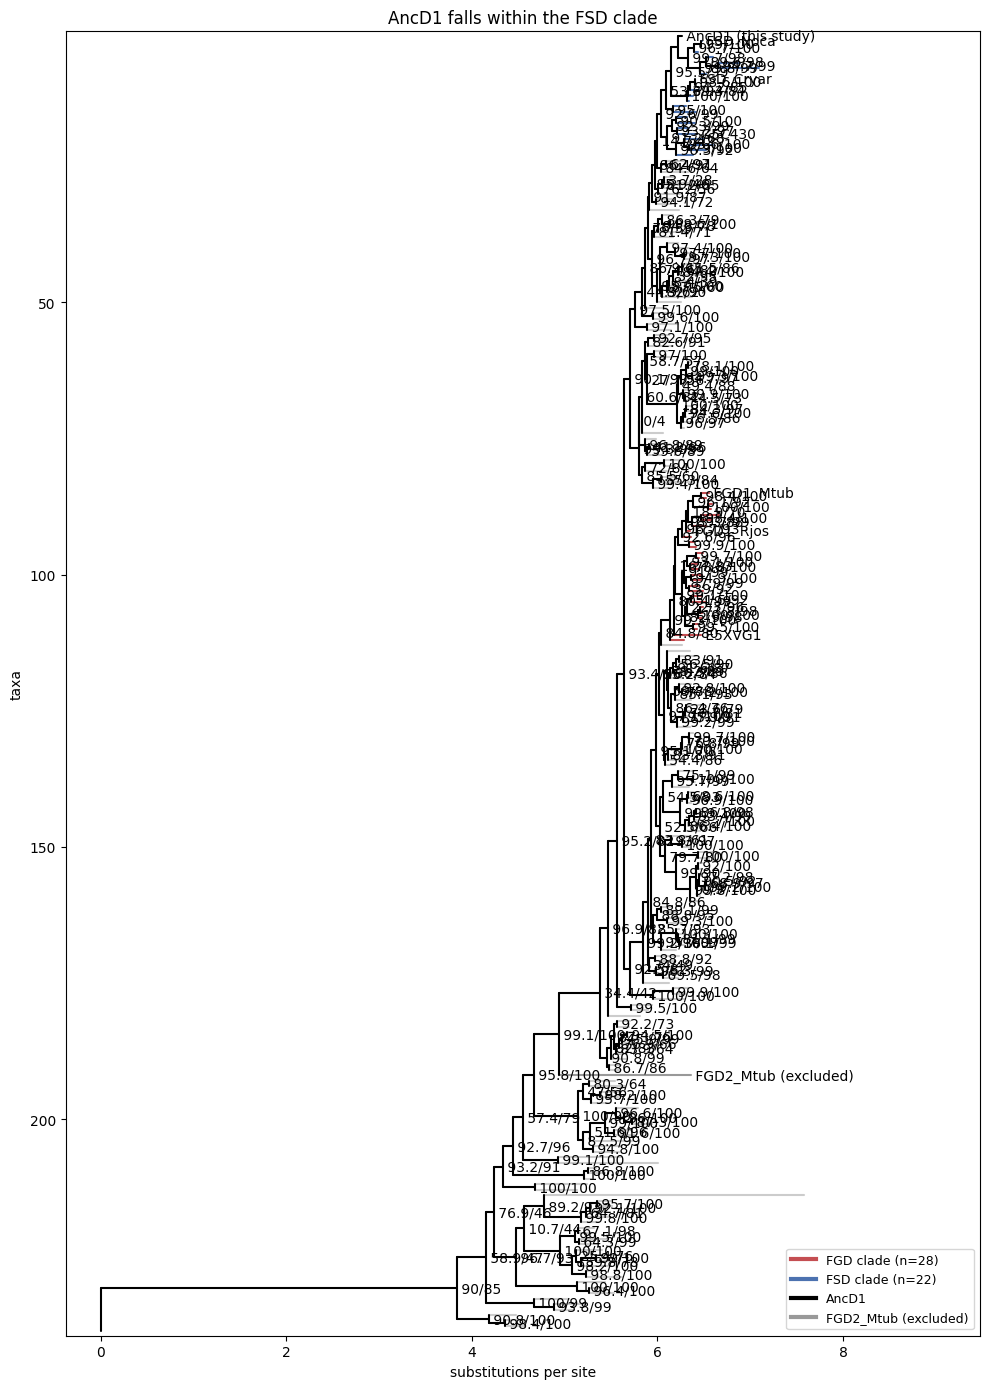

saved tree_groups.png


In [28]:
import json
from Bio import Phylo
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

groups = json.load(open("stage3_groups.json"))
name_map = json.load(open("name_map.json"))
FGD_SET = set(groups["FGD"]["tips"])
FSD_SET = set(groups["FSD"]["tips"])
ANC = groups.get("AncD1_tip")
FGD2 = next((s for s, i in name_map.items() if i["label"] == "FGD2_Mtub"), None)

tr = Phylo.read("tree_rooted_outgroup.nwk", "newick")

COL = {"fgd": "#C44E52", "fsd": "#4C72B0", "anc": "#000000",
       "excl": "#999999", "other": "#CCCCCC"}

def kind(tip):
    if tip == ANC:  return "anc"
    if tip == FGD2: return "excl"
    if tip in FGD_SET: return "fgd"
    if tip in FSD_SET: return "fsd"
    return "other"

colors, labels = {}, {}
for t in tr.get_terminals():
    k = kind(t.name)
    colors[t.name] = COL[k]
    lab = name_map.get(t.name, {}).get("label", "")
    if k == "anc":
        labels[t.name] = "AncD1 (this study)"
    elif k == "excl":
        labels[t.name] = "FGD2_Mtub (excluded)"
    elif not lab.startswith("A0A") and lab != t.name and k in ("fgd", "fsd"):
        labels[t.name] = lab
    else:
        labels[t.name] = ""

for t in tr.get_terminals():
    t.color = colors[t.name]
    t.name = labels[t.name]

fig = plt.figure(figsize=(10, 14))
ax = fig.add_subplot(111)
Phylo.draw(tr, axes=ax, do_show=False, show_confidence=False)
ax.set_xlabel("substitutions per site")
ax.set_title("AncD1 falls within the FSD clade")
ax.legend(handles=[
    Line2D([0], [0], color=COL["fgd"], lw=3, label=f"FGD clade (n={len(FGD_SET)})"),
    Line2D([0], [0], color=COL["fsd"], lw=3, label=f"FSD clade (n={len(FSD_SET)})"),
    Line2D([0], [0], color=COL["anc"], lw=3, label="AncD1"),
    Line2D([0], [0], color=COL["excl"], lw=3, label="FGD2_Mtub (excluded)"),
], loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig("tree_groups.png", dpi=200)
plt.show()
print("saved tree_groups.png")

In [29]:
lines = ["DATASET_STYLE", "SEPARATOR TAB", "DATASET_LABEL\tclade groups",
         "COLOR\t#000000", "DATA"]
labs = ["LABELS", "SEPARATOR TAB", "DATA"]

for t, info in name_map.items():
    k = kind(t)
    if k == "other":
        continue
    c = COL[k]
    lines.append(f"{t}\tlabel\tnode\t{c}\t1\tbold")
    lab = info.get("label", t)
    if k == "anc":
        labs.append(f"{t}\tAncD1 (this study)")
    elif k == "excl":
        labs.append(f"{t}\tFGD2_Mtub (excluded)")
    elif not lab.startswith("A0A"):
        labs.append(f"{t}\t{lab}")

open("itol_styles.txt", "w").write("\n".join(lines) + "\n")
open("itol_labels.txt", "w").write("\n".join(labs) + "\n")
print("wrote itol_styles.txt and itol_labels.txt")
print("upload tree_rooted_outgroup.nwk to itol.embl.de, then drag both files on")

wrote itol_styles.txt and itol_labels.txt
upload tree_rooted_outgroup.nwk to itol.embl.de, then drag both files on


In [31]:
import os, zipfile
from google.colab import files

print("working directory:", os.getcwd())
all_files = sorted(os.listdir("."))
print(f"{len(all_files)} items here\n")

KEEP_EXT = (".csv", ".json", ".nwk", ".treefile", ".fasta",
            ".png", ".pdf", ".iqtree", ".txt", ".log")
found = [f for f in all_files
         if f.endswith(KEEP_EXT) and os.path.isfile(f)
         and os.path.getsize(f) > 0]

print("result files found:")
for f in found:
    print(f"   {f:45s} {os.path.getsize(f)/1024:8.1f} KB")

KEY = ["sdp_ranked.csv", "sdp_with_structure.csv",
       "substitutions_F_vs_S_renum.csv", "ancd1_fgd_like_positions_renum.csv",
       "ancestral_seqs.fasta", "stage3_groups.json", "trimcol_to_ancd1.json",
       "tree_rooted_outgroup.nwk"]
missing = [f for f in KEY if f not in found]
print(f"\nkey results present: {len(KEY)-len(missing)} of {len(KEY)}")
if missing:
    print("MISSING:", ", ".join(missing))

if found:
    OUT = "ancd1_results.zip"
    if os.path.exists(OUT):
        os.remove(OUT)
    with zipfile.ZipFile(OUT, "w", zipfile.ZIP_DEFLATED) as z:
        for f in found:
            if f != OUT:
                z.write(f)
    print(f"\n{OUT}: {os.path.getsize(OUT)/1024:.0f} KB")
    files.download(OUT)
else:
    print("\nnothing to zip - the runtime was probably reclaimed")

working directory: /content/ancd1_phylo
43 items here

result files found:
   aln_clustalo.fasta                               137.7 KB
   aln_mafft.fasta                                  157.1 KB
   aln_trimmed.fasta                                 76.6 KB
   ancd1_asr.iqtree                                  45.7 KB
   ancd1_asr.log                                     12.8 KB
   ancd1_asr.treefile                                 9.9 KB
   ancd1_fgd_like_positions.csv                       0.4 KB
   ancd1_fgd_like_positions_renum.csv                 0.5 KB
   ancd1_set_final.fasta                            106.7 KB
   ancd1_tree.iqtree                                 89.3 KB
   ancd1_tree.log                                    21.0 KB
   ancd1_tree.treefile                               10.0 KB
   ancestral_seqs.fasta                               1.1 KB
   asr_nodes.json                                     0.0 KB
   asr_summary.json                                   0.3 KB
   input_s

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

FGD clade 28 seqs, support 99.3/100
FSD clade 22 seqs (+AncD1), support 92.6/99
pruning 185 tips, keeping 6
figure has 6 tips


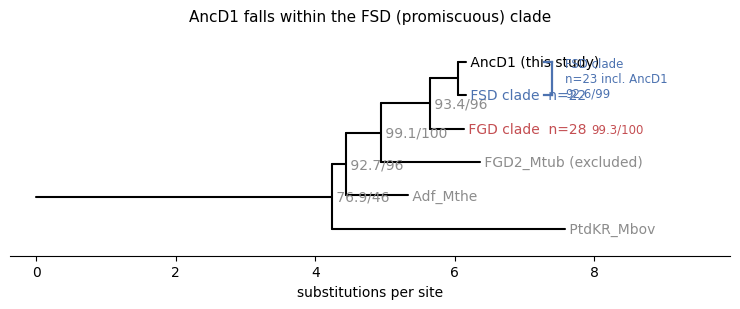


wrote tree_figure.png (300 dpi) and tree_figure.pdf (vector)

CAPTION DRAFT
--------------------------------------------------------------
Maximum-likelihood phylogeny of 239 F420-dependent dehydrogenase
sequences, inferred with IQ-TREE under LG+F+I+G4. The FGD and FSD
clades are collapsed; n gives the number of sequences in each, and
values in parentheses are SH-aLRT / ultrafast bootstrap support.
AncD1 is shown separately within the FSD clade. FGD2_Mtub branches
outside the FGD clade and was excluded from clade-level analyses.
The tree is rooted on alanine racemase (T. marianensis, UniProt
E6SIZ8), which is omitted from the figure for clarity.


In [32]:
# ============================================================
#  PUBLICATION TREE FIGURE  (prune, do not collapse)
#
#  Collapsing left blank tips behind, and the outgroup's very
#  long branch compressed everything else. This instead PRUNES
#  the tree to the elements that carry the argument:
#
#     FGD clade (one tip)     AncD1
#     FSD clade (one tip)     FGD2_Mtub, Adf_Mthe, PtdKR_Mbov
#
#  The outgroup is dropped from the drawing - its branch is
#  several substitutions per site and flattens the rest - and
#  the rooting is stated in the caption instead.
#
#  Outputs tree_figure.png (300 dpi) and tree_figure.pdf
# ============================================================
import json
from Bio import Phylo
from Bio.Phylo.BaseTree import Clade
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

SHOW_OUTGROUP = False      # True puts the racemase back in

groups = json.load(open("stage3_groups.json"))
name_map = json.load(open("name_map.json"))
label = {s: i["label"] for s, i in name_map.items()}
clade_of = {s: i["clade"] for s, i in name_map.items()}

FGD_SET = set(groups["FGD"]["tips"])
FSD_SET = set(groups["FSD"]["tips"])
ANC = groups.get("AncD1_tip")
OUT = next((s for s in name_map if clade_of[s] == "OUTGROUP"), None)

NAMED = {}
for s, i in name_map.items():
    if i["label"] in ("FGD2_Mtub", "Adf_Mthe", "PtdKR_Mbov"):
        NAMED[s] = i["label"]

tree = Phylo.read("tree_rooted_outgroup.nwk", "newick")
tips = {t.name: t for t in tree.get_terminals()}
N_TOTAL = len(tips)


def sup(cl):
    s = str(cl.confidence) if cl.confidence is not None else (cl.name or "")
    return s if ("/" in s or s.replace(".", "").isdigit()) else ""


fgd_mrca = tree.common_ancestor([tips[t] for t in FGD_SET if t in tips])
fsd_mrca = tree.common_ancestor([tips[t] for t in (FSD_SET | {ANC}) if t in tips])
FGD_SUP, FSD_SUP = sup(fgd_mrca), sup(fsd_mrca)
print(f"FGD clade {len(FGD_SET)} seqs, support {FGD_SUP}")
print(f"FSD clade {len(FSD_SET)} seqs (+AncD1), support {FSD_SUP}")

# --- replace the two clades with single tips, keeping AncD1 separate ---
fsd_mrca.clades = [
    Clade(branch_length=0.12, name="AncD1 (this study)"),
    Clade(branch_length=0.12, name=f"FSD clade  n={len(FSD_SET)}"),
]
fsd_mrca.name, fsd_mrca.confidence = None, None

fgd_mrca.clades = []
fgd_mrca.name = f"FGD clade  n={len(FGD_SET)}"
fgd_mrca.confidence = None

# --- rename the handful of tips we keep, then prune the rest ---
KEEP = {"AncD1 (this study)", f"FSD clade  n={len(FSD_SET)}",
        f"FGD clade  n={len(FGD_SET)}"}
for t in tree.get_terminals():
    if t.name in NAMED:
        t.name = ("FGD2_Mtub (excluded)" if NAMED[t.name] == "FGD2_Mtub"
                  else NAMED[t.name])
        KEEP.add(t.name)
    elif t.name == OUT and SHOW_OUTGROUP:
        t.name = "alanine racemase (outgroup)"
        KEEP.add(t.name)

drop = [t for t in tree.get_terminals() if t.name not in KEEP]
print(f"pruning {len(drop)} tips, keeping {len(KEEP)}")
for t in drop:
    try:
        tree.prune(t)
    except Exception:
        pass

print(f"figure has {len(tree.get_terminals())} tips")
Phylo.write(tree, "tree_collapsed.nwk", "newick")

# --- draw ---
COL = {"FGD": "#C44E52", "FSD": "#4C72B0", "ANC": "#000000", "GREY": "#8C8C8C"}


def tip_colour(name):
    n = str(name or "")
    if "AncD1" in n:
        return COL["ANC"]
    if n.startswith("FGD clade"):
        return COL["FGD"]
    if n.startswith("FSD clade"):
        return COL["FSD"]
    return COL["GREY"]


n_tips = len(tree.get_terminals())
fig = plt.figure(figsize=(7.5, max(3.2, n_tips * 0.52)))
ax = fig.add_subplot(111)
Phylo.draw(tree, axes=ax, do_show=False, show_confidence=False,
           label_colors=tip_colour)

ax.set_xlabel("substitutions per site", fontsize=10)
ax.set_ylabel("")
ax.set_yticks([])
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.set_title("AncD1 falls within the FSD (promiscuous) clade",
             fontsize=11, pad=10)

# --- bracket showing that AncD1 sits INSIDE the FSD clade ---
order = [t.name for t in tree.get_terminals()]
ys = {nm: i + 1 for i, nm in enumerate(order)}
anc_y = ys.get("AncD1 (this study)")
fsd_y = ys.get(f"FSD clade  n={len(FSD_SET)}")

if anc_y and fsd_y:
    x0, x1 = ax.get_xlim()
    bx = x1 * 0.78                      # bracket sits right of the labels
    lo, hi = min(anc_y, fsd_y), max(anc_y, fsd_y)
    ax.plot([bx, bx], [lo, hi], color=COL["FSD"], lw=1.6,
            clip_on=False, zorder=5)
    for yy in (lo, hi):
        ax.plot([bx, bx - x1 * 0.012], [yy, yy], color=COL["FSD"],
                lw=1.6, clip_on=False, zorder=5)
    ax.text(bx + x1 * 0.02, (lo + hi) / 2,
            f"FSD clade\nn={len(FSD_SET) + 1} incl. AncD1\n{FSD_SUP}",
            va="center", ha="left", fontsize=8.5, color=COL["FSD"],
            clip_on=False)
    ax.set_xlim(x0, x1 * 1.05)

# support value printed beside the FGD clade tip
fgd_y = ys.get(f"FGD clade  n={len(FGD_SET)}")
if fgd_y:
    x1 = ax.get_xlim()[1]
    ax.text(x1 * 0.80, fgd_y, f"{FGD_SUP}", va="center", ha="left",
            fontsize=8.5, color=COL["FGD"], clip_on=False)
# no legend: the coloured labels and the bracket already say it

plt.tight_layout()
plt.savefig("tree_figure.png", dpi=300, bbox_inches="tight")
plt.savefig("tree_figure.pdf", bbox_inches="tight")
plt.show()

print("\nwrote tree_figure.png (300 dpi) and tree_figure.pdf (vector)")
print("\nCAPTION DRAFT")
print("-" * 62)
print(f"Maximum-likelihood phylogeny of {N_TOTAL} F420-dependent dehydrogenase")
print("sequences, inferred with IQ-TREE under LG+F+I+G4. The FGD and FSD")
print("clades are collapsed; n gives the number of sequences in each, and")
print("values in parentheses are SH-aLRT / ultrafast bootstrap support.")
print("AncD1 is shown separately within the FSD clade. FGD2_Mtub branches")
print("outside the FGD clade and was excluded from clade-level analyses.")
if not SHOW_OUTGROUP:
    print("The tree is rooted on alanine racemase (T. marianensis, UniProt")
    print("E6SIZ8), which is omitted from the figure for clarity.")


In [33]:
# ============================================================
#  SUPPLEMENTARY FIGURE: everything shown
#
#  Every tip labelled accession_ORGANISM, every node carrying a
#  support value, clades coloured. This is the convention for a
#  supplementary phylogeny and is what readers expect to be able
#  to check.
#
#  It is a large sheet by design: ~48 inches tall as vector PDF.
#  Zoom or print it; nothing is hidden.
# ============================================================
import json, re
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from Bio import Phylo

IN_PER_TIP   = 0.20
TIP_FONTSIZE = 5.0
SUP_FONTSIZE = 3.8
CLADOGRAM    = True     # branch lengths are dominated by the outgroup

groups = json.load(open("stage3_groups.json"))
name_map = json.load(open("name_map.json"))
label = {s: i["label"] for s, i in name_map.items()}
clade_of = {s: i["clade"] for s, i in name_map.items()}

FGD_SET = set(groups["FGD"]["tips"])
FSD_SET = set(groups["FSD"]["tips"])
ANC = groups.get("AncD1_tip")
OUT = next((s for s in name_map if clade_of[s] == "OUTGROUP"), None)
NAMED_REFS = {"FGD1_Mtub", "FGD1_Rjos", "FGD2_Mtub", "FSD_Noca", "FSD_Cryar",
              "Adf_Mthe", "PtdKR_Mbov", "AlaRac_Tmar"}

COL_FGD, COL_FSD, COL_ANC = "#C44E52", "#2B6CB0", "#000000"
COL_GREY, COL_OTHER = "#777777", "#444444"


def org_code(desc):
    """Thermosporothrix hazakensis -> THEHA, UniProt-mnemonic style."""
    m = re.search(r"OS=([A-Z][a-z]+)\s+([a-z]+)", desc or "")
    if not m:
        m2 = re.search(r"OS=([A-Z][a-z]+)", desc or "")
        return (m2.group(1)[:5].upper() if m2 else "UNKNOWN")
    return (m.group(1)[:3] + m.group(2)[:2]).upper()


tree = Phylo.read("tree_rooted_outgroup.nwk", "newick")
n_tips = len(tree.get_terminals())


def parse_sup(cl):
    s = str(cl.confidence) if cl.confidence is not None else (cl.name or "")
    if "/" in s:
        a, b = s.split("/", 1)
        try:
            return float(a), float(b), s
        except ValueError:
            return None, None, s
    return None, None, s


# keep every support value, as text on the node
n_sup = 0
for cl in tree.get_nonterminals():
    a, b, raw = parse_sup(cl)
    cl.confidence = None
    cl.name = raw if raw else None
    n_sup += bool(raw)
print(f"{n_tips} tips, {n_sup} support values retained of "
      f"{len(tree.get_nonterminals())} internal nodes")

if CLADOGRAM:
    for cl in tree.find_clades():
        cl.branch_length = 1.0


def kind(tip):
    if tip == ANC:  return "anc"
    if tip in FGD_SET: return "fgd"
    if tip in FSD_SET: return "fsd"
    if tip == OUT or label.get(tip) == "FGD2_Mtub": return "grey"
    return "other"


COLOUR = {"anc": COL_ANC, "fgd": COL_FGD, "fsd": COL_FSD,
          "grey": COL_GREY, "other": COL_OTHER}

tip_kind = {}
for t in tree.get_terminals():
    info = name_map.get(t.name, {})
    k = kind(t.name)
    lab, acc = info.get("label", t.name), info.get("accession", "")
    if t.name == ANC:
        txt = "AncD1  (THIS STUDY)"
    elif lab in NAMED_REFS:
        txt = f"{lab}  {acc}"
    else:
        txt = f"{acc}_{org_code(info.get('description', ''))}"
    tip_kind[txt] = k
    t.color = COLOUR[k]
    t.name = txt

height = max(10, n_tips * IN_PER_TIP)
fig = plt.figure(figsize=(11, height))
ax = fig.add_subplot(111)
matplotlib.rcParams["font.size"] = SUP_FONTSIZE

Phylo.draw(tree, axes=ax, do_show=False, show_confidence=True,
           label_colors=lambda s: COLOUR.get(tip_kind.get(s, "other"), COL_OTHER))

# tip labels are drawn by Phylo.draw at the default size; bump them up
for txt in ax.texts:
    if txt.get_text() in tip_kind:
        txt.set_fontsize(TIP_FONTSIZE)
    else:
        txt.set_fontsize(SUP_FONTSIZE)
        txt.set_color("#8A6D3B")

ax.set_xlabel("nodes from root (cladogram; branch lengths not to scale)"
              if CLADOGRAM else "substitutions per site", fontsize=9)
ax.set_ylabel("")
ax.set_yticks([])
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.tick_params(axis="x", labelsize=8)

ax.legend(handles=[
    Line2D([0], [0], color=COL_FGD, lw=3, label=f"FGD clade (n={len(FGD_SET)})"),
    Line2D([0], [0], color=COL_FSD, lw=3, label=f"FSD clade (n={len(FSD_SET)})"),
    Line2D([0], [0], color=COL_ANC, lw=3, label="AncD1 (this study)"),
    Line2D([0], [0], color=COL_GREY, lw=3, label="outgroup / excluded"),
], loc="lower right", fontsize=8, frameon=False)

plt.tight_layout()
plt.savefig("tree_full_detailed.pdf", bbox_inches="tight")
plt.savefig("tree_full_detailed.png", dpi=150, bbox_inches="tight")
plt.close()
print(f"wrote tree_full_detailed.pdf ({height:.0f} in tall) and .png")
print("\nTip labels are accession_ORGANISM (UniProt mnemonic style).")
print("Node values are SH-aLRT / ultrafast bootstrap.")

239 tips, 236 support values retained of 238 internal nodes
wrote tree_full_detailed.pdf (48 in tall) and .png

Tip labels are accession_ORGANISM (UniProt mnemonic style).
Node values are SH-aLRT / ultrafast bootstrap.


---

## Checkpoint

1. **Did all three rootings agree?** This gates Stage 2.
2. **Are the FGD and FSD reference clades each monophyletic?** If a reference lands in the
   wrong clade, that's a finding, not a bug — but we need to understand it before using
   clade membership to define the Stage 3 comparison groups.
3. **Where does FGD2_Mtub fall?** It was the odd one out in the Stage 1a identity check.
   If it sits outside the FGD clade, exclude it from the Stage 3 FGD group.
4. **What bootstrap support does the FGD/FSD split have?** Under 95 UFBoot weakens
   everything downstream and should be stated plainly.
5. **Retained column fraction after trimAl** — note it for the methods.